# EDA: Hyperallergic Pages and Organizer Pages

The Organizer Pages are the pages we obtained from the links in the opportunities/pages we scrapped from the Hyperallergic website.

In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re

### Load and Join



In [49]:
# listings = pd.read_json("data/hyperallergic.jsonl", lines=True) # to tell pandas to read the file line by line
## this won't work as it does on local computer, first we need to connect to my google drive

In [50]:
# !ls -F data/

In [51]:
# from google.colab import drive
# drive.mount('/content/drive')

# Now we can read a file, for example:
# file_path = '/content/drive/MyDrive/your_file_name.csv'
# df = pd.read_csv(file_path)
# print(df.head())

In [52]:
# file_path = '/content/drive/MyDrive/DLArtManager/data/hyperallergic.jsonl'
# listings = pd.read_json(file_path, lines=True)

file_path = '../data/raw/hyperallergic.jsonl'
listings = pd.read_json(file_path, lines=True)

np.random.seed(1)
display(listings.sample(10))

,title,description,deadline,fees,website,raw_text,type,source,source_url,published_at,scraped_at
363,Collar Works – Elizabeth Murray Artist Residency,"Held on a 77-acre farm in Granville, New York, this residency offers studio ...","September 1, 2024",NaN,https://www.collarworks.org/emar,Collar Works – Elizabeth Murray Artist Residency\nHeld on a 77-acre farm in ...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-august-2024/,2024-08-01 19:00:00+00:00,2026-10-07 05:46:54+00:00
62,Banff Centre for Arts and Creativity – Visual Arts Thematic Residencies,Develop your work in a Visual Arts residency at Banff Centre. Access excepti...,"May 6, 2026 (Visual Arts Thematic – On Other Archives), June 3, 2026 (Visual...",The application fee is $65 ($35 for applicants who identify as Indigenous).,https://www.banffcentre.ca/visual-arts,Banff Centre for Arts and Creativity – Visual Arts Thematic Residencies\nDev...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-april-2026/,2026-04-02 12:00:28+00:00,2026-10-07 05:46:54+00:00
322,Visual AIDS – Postcards From the Edge,"Donate an original, postcard-sized artwork to this benefit supporting artist...","November 22, 2024",NaN,https://www.postcards.visualaids.org/,"Visual AIDS – Postcards From the Edge\nDonate an original, postcard-sized ar...",Open Call,hyperallergic,https://hyperallergic.com/opportunities-november-2024/,2024-11-01 16:00:00+00:00,2026-10-07 05:46:54+00:00
92,Textile Arts Center – Artist in Residence Cycle 18,"Providing an opportunity to explore the textile medium, TAC AIR combines stu...","March 6, 2026","Tuition is $11,000, the application fee is $35.",https://textileartscenter.com/artist-opportunities/artist-in-residence/,Textile Arts Center – Artist in Residence Cycle 18\nProviding an opportunity...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-in-february-2026/,2026-02-02 21:36:57+00:00,2026-10-07 05:46:54+00:00
146,at Louis Place – Artist Publishing Cohort,This new initiative offers personalized support for eight artists with publi...,"October 24, 2025",NaN,https://atlouisplace.com/cohort,at Louis Place – Artist Publishing Cohort\nThis new initiative offers person...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-october-2025/,2025-10-01 18:00:00+00:00,2026-10-07 05:46:54+00:00
338,Open Source – 2026 Exhibition Open Call,Applications are sought from artists worldwide working in any medium whose p...,"November 3, 2024",Selected artists will receive fees based on the W.A.G.E.,https://open-source-gallery.org/open-call-for-2026-exhibitions/,Open Source – 2026 Exhibition Open Call\nApplications are sought from artist...,Open Call,hyperallergic,https://hyperallergic.com/opportunities-october-2024/,2024-10-01 20:36:05+00:00,2026-10-07 05:46:54+00:00
242,Pratt Institute – Climate Studio Residency,"Artists, educators, and community organizers with an interest in climate lit...","April 15, 2025",NaN,https://www.pratt.edu/liberal-arts-and-sciences/math-and-science/climate-stu...,"Pratt Institute – Climate Studio Residency\nArtists, educators, and communit...",Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-april-2025/,2025-04-02 16:30:00+00:00,2026-10-07 05:46:54+00:00
271,Onassis AiR Open Call 2025/26 – Residencies and Fellowships,"Participants in the Onassis AiR residency programs in Athens, Greece, receiv...","March 7, 2025 (12am EST/12pm UTC+2)","Participants in the Onassis AiR residency programs in Athens, Greece, receiv...",https://www.onassis.org/open-calls/onassis-air-open-call-2025-26,Featured\nOnassis AiR Open Call 2025/26 – Residencies and Fellowships\nParti...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-february-2025/,2025-02-03 18:55:54+00:00,2026-10-07 05:46:54+00:00
29,"Two Artist Fellowships - Hodder & PAF — Princeton University, Lewis Center f...","Princeton Arts Fellowships - 2 years, teaching required,

It is the text between the title and the "Deadline:" label. For ArtFields, that is "Southern artists: compete for $100K+ in prizes ... Fee: $25".

In [53]:
listings.description[1]

'Manhattan-based individual artists, collectives, and non-profit organizations working across all artistic disciplines, backgrounds and neighborhoods are invited to apply for project and/or unrestricted grant support!'

In [54]:
listings.shape

(407, 11)

We have about 400 opportunities, we need to find duplicates in them.

In [55]:
listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 407 entries, 0 to 406
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   title         407 non-null    str                
 1   description   407 non-null    str                
 2   deadline      400 non-null    str                
 3   fees          94 non-null     str                
 4   website       407 non-null    str                
 5   raw_text      407 non-null    str                
 6   type          407 non-null    str                
 7   source        407 non-null    str                
 8   source_url    407 non-null    str                
 9   published_at  407 non-null    datetime64[us, UTC]
 10  scraped_at    407 non-null    datetime64[us, UTC]
dtypes: datetime64[us, UTC](2), str(9)
memory usage: 356.1 KB


In [56]:
listings.isnull().sum()

title             0
description       0
deadline          7
fees            313
website           0
raw_text          0
type              0
source            0
source_url        0
published_at      0
scraped_at        0
dtype: int64

- fees has a lot of missing values - are these missing fees values in the possting or were we just not able to parse them?
- we do need all the deadlines so need to investigate these missing 7 deadline values
- the datatypes of all the features look okay for now; even though fees and deadline are in their correct datatypes, we probably don't need them to be to suggest it to the artist user

In [57]:
file_path = '../data/raw/opportunity_pages.jsonl'
pages = pd.read_json(file_path, lines=True)

np.random.seed(1)
display(pages.sample(10))

,source_url,raw_text,published_at,scraped_at
67,https://www.dagfoundation.org/the-dag-prize,top of page\n\nSkip to Main Content\n\nMenu\n\n# DAG Prize Application\n\n![...,NaN,2026-10-07 06:05:12+00:00
250,https://www.redlineart.org/insite-fund,Apply for the INSITE Fund Colorado Artist Grant Today! — RedLine Contemporar...,NaN,2026-10-07 06:29:42+00:00
230,https://centerforbookarts.org/artists-in-residence,[Skip to content](https://centerforbookarts.org/artists-in-residence#content...,NaN,2026-10-07 06:27:37+00:00
161,https://artportkingston.org/new-page-56,ArtPort Kingston\n\n[![ArtPort Kingston](https://images.squarespace-cdn.com/...,NaN,2026-10-07 06:19:09+00:00
91,https://www.artistsandmothers.org/grant,#### Grant Guidelines\n\nArtists & Mothers is committed to supporting artist...,NaN,2026-10-07 06:07:38+00:00
224,https://tyler.temple.edu/sites/tyler/files/Edgar Heap of Birds Family Artist...,## Position Announcement Tyler School of Art and Architecture Edgar Heap of ...,NaN,2026-10-07 06:26:53+00:00
58,https://franklinfurnace.org/grants-and-funding/the-fund/,[Skip to content](https://franklinfurnace.org/grants-and-funding/the-fund/#c...,NaN,2026-10-07 06:04:16+00:00
234,https://www.radcliffe.harvard.edu/radcliffe-fellowship/become-a-radcliffe-fe...,[Skip to main content](https://www.radcliffe.harvard.edu/radcliffe-fellowshi...,NaN,2026-10-07 06:28:02+00:00
180,https://www.galleryovissi.com/ovissi-foundation,We couldn't find the page you were looking for. This is either because:\n\n-...,NaN,2026-10-07 06:22:32+00:00
4,https://apexart.org/opencalls.php,"## OPEN CALLS\n\napexart's Open Calls are opportunities for artists, curator...",NaN,2026-10-07 05:54:49+00:00


In [58]:
print(pages.shape)
pages.info()

(251, 4)
<class 'pandas.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   source_url    251 non-null    str                
 1   raw_text      251 non-null    str                
 2   published_at  15 non-null     str                
 3   scraped_at    251 non-null    datetime64[us, UTC]
dtypes: datetime64[us, UTC](1), str(3)
memory usage: 2.4 MB


In [59]:
# from scrapers.hyperallergic.common import url_key # this is not gonna work as the module is not in the path, we need to add it to the path first

In [60]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":   # a notebook usually starts in its own folder
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "scrapers")) # went into scrapers folder to import common.py, so that we can use url_key function

from common import url_key # url_key is a function that takes a url and returns a unique key for that url-useful for deduplication (also clean urls - removing their trailing slashes, query parameters, etc.)


In [61]:
pd.set_option('display.max_colwidth', None)
pages['raw_text'].sample(5)

242                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

Some issues in the text that we should be aware of:

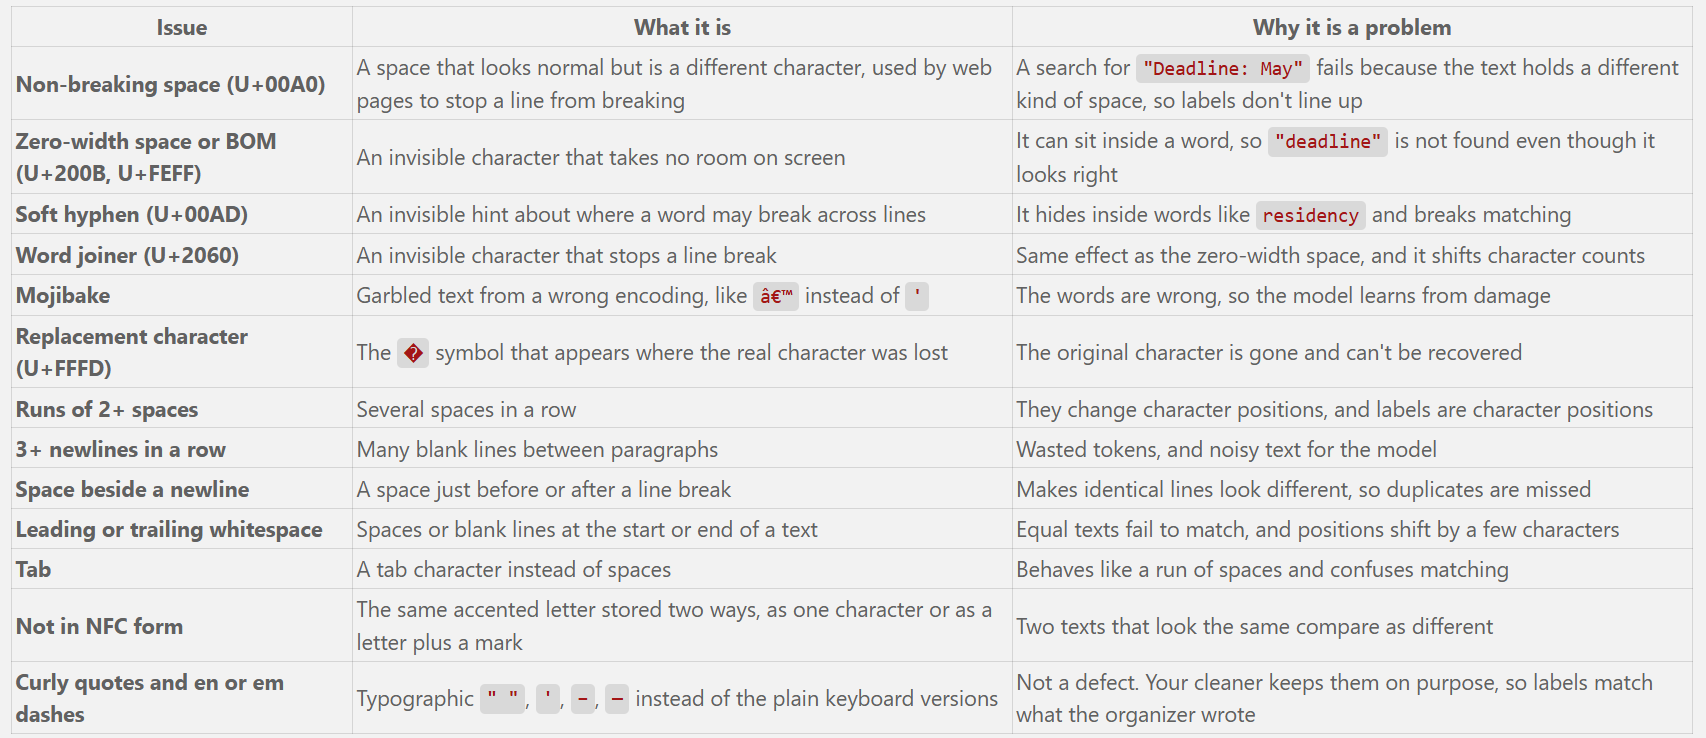

The main reason all of this matters: labels are character positions (start and end), and a model is trained on exactly the text those positions refer to. Anything that adds, hides, or changes characters after labeling shifts those positions. That is why your cleaner's docstring says to run it once, before labeling.

In [62]:
import re, unicodedata, collections

checks = {
    "non-breaking space": lambda t: "\u00a0" in t,
    "zero-width / BOM":   lambda t: re.search("[\u200b\u200c\u200d\ufeff]", t) is not None,
    "mojibake":           lambda t: re.search("Ã.|â€|Â|\ufffd", t) is not None,
    "2+ spaces":          lambda t: "  " in t,
    "3+ newlines":        lambda t: "\n\n\n" in t,
    "edge whitespace":    lambda t: t != t.strip(),
}
for name, fn in checks.items():
    print(name, sum(fn(t) for t in pages["raw_text"]), "of", len(pages))

# every unusual character, with its name
c = collections.Counter(ch for t in pages["raw_text"] for ch in t
                        if ord(ch) > 127 and unicodedata.category(ch) in ("Zs", "Cf", "Cc"))
for ch, n in c.most_common(10):
    print(f"U+{ord(ch):04X}", unicodedata.name(ch, "?"), n)



non-breaking space 132 of 251
zero-width / BOM 17 of 251
mojibake 0 of 251
2+ spaces 76 of 251
3+ newlines 102 of 251
edge whitespace 2 of 251
U+00A0 NO-BREAK SPACE 2081
U+200B ZERO WIDTH SPACE 135
U+00AD SOFT HYPHEN 59
U+2060 WORD JOINER 43
U+202F NARROW NO-BREAK SPACE 28
U+200D ZERO WIDTH JOINER 26
U+2009 THIN SPACE 26
U+200E LEFT-TO-RIGHT MARK 8
U+FEFF ZERO WIDTH NO-BREAK SPACE 3
U+200A HAIR SPACE 1


1. At first let's deal with urls in the listings to become unique, we will use url_key function to do that, and then we will check if there are any duplicates in the listings based on the url_key 

2. We want that our model should train on one set of listings, as in the listings coming from one set of organizers and then test it on another. The test is meant to show how it does on listings it has never seen.

Organizers repeat themselves, (for ex: apexart appears 7 times in the data,) usually with almost the same wording and layout. If some apexart listings are in the training set and others in the test set, the model has already seen apexart's style. It scores well on the test by recognizing the organizer, not by understanding the text. 

This could lead to leakage, and makes the score look better than it really is. So we'll create a function 'domain' in which we group listings by domain(url) and send each group entirely to train or entirely to test - a group split. A model that does well on it has to handle organizers it has never seen, which is what it will meet in real use.



Example: domain takes a link such as https://www.apexart.org/opencalls.php and returns the site, apexart.org, without the www.. That site name stands for the organizer.


In [63]:

from urllib.parse import urlparse
def domain(url):
    """The site of a link, without "www.". 
    Used to keep an organizer out of both train and test."""
    host = urlparse(url or "").netloc.lower()
    return host[4:] if host.startswith("www.") else host


listings["key"] = listings["website"].map(url_key)
pages["key"] = pages["source_url"].map(url_key)
listings["domain"] = listings["website"].map(domain)


Next, 
1. we also want to extract the month from the source_url, so that we can use it for later analysis, for example, to see if there is any seasonality in the data. We can do this by using the month_from_source_url function from the preprocess.clean module.

2. Very important for us to know 'why an organizer page is not usable text', or 'None' if it looks fine.

    "empty" is almost no text. "not_found" is an error page (the start of the
    text says the page is missing). "no_signal" is a page with no words a
    listing would use, such as a login wall or a cookie banner.
  


In [64]:
# extract month from source_url using the month_from_source_url function

MONTHS = {m: i for i, m in enumerate(
    ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], start=1)}

def month_from_source_url(url):
    """The month of a Hyperallergic post, such as "2025-04", from its address."""
    m = re.search(r"opportunities-(?:in-)?([a-z]+)-(\d{4})", url or "")
    if not m or m[1][:3] not in MONTHS:
        return None
    return f"{m[2]}-{MONTHS[m[1][:3]]:02d}"

# what the problem is with the page, using the page_problem function
def page_problem(text):
    """Say why an organizer page is not usable text, or None if it looks fine.

    "empty" is almost no text. "not_found" is an error page (the start of the
    text says the page is missing). "no_signal" is a page with no words a
    listing would use, such as a login wall or a cookie banner.
    """
    text = normalize_text(text)
    if len(text) < 200:
        return "empty"
    if _NOT_FOUND.search(text[:400]):
        return "not_found"
    if not _OPPORTUNITY_WORDS.search(text):
        return "no_signal"
    return None

import ftfy

_NOT_FOUND = re.compile(
    r"page not found|(?:couldn.t|can.t|could not) find (?:the|that) page|no longer (?:available|exists)|\b404\b", re.I
)
_OPPORTUNITY_WORDS = re.compile(
    r"\b(deadline|appl(?:y|ying|ication)|eligib|grant|residenc|fellowship|open call|submission|artist)", re.I
)


def normalize_text(text):
    """Make whitespace and invisible characters consistent.

    Fixes broken encodings, turns non-breaking spaces into plain spaces, drops
    zero-width characters, and collapses runs of spaces and blank lines. Curly
    quotes and en dashes are kept, because labels will be made on this text
    and should match what the organizer wrote. Run this once, before labeling:
    character positions change if it is run afterwards.
    """
    if not isinstance(text, str):
        return ""
    text = ftfy.fix_text(text)
    text = unicodedata.normalize("NFC", text)
    text = text.replace(" ", " ")
    text = re.sub(r"[​‌‍﻿]", "", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" ?\n ?", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

    
listings["month"] = listings["source_url"].map(month_from_source_url)
pages["problem"] = pages["raw_text"].map(page_problem)

print(pages["problem"].value_counts(dropna=False))

problem
NaN          226
not_found     14
no_signal      7
empty          4
Name: count, dtype: int64


25 of the 251 fetched pages are not usable (226 are): 14 are "page not found", 7 have no listing words (login walls, banners), 4 are nearly empty.

In [65]:
## now let's merge the listings and pages dataframes on the key column, using an inner join, 
# and keep only the columns we need: key, domain, month, raw_text, problem

df = listings.merge(pages[["key", "raw_text", "problem"]].rename(columns={"raw_text": "page_text"}),
                    on="key", how="left")
df["has_page"] = df["page_text"].notna()
df["page_usable"] = df["has_page"] & df["problem"].isna()

In [66]:
print(df.head())
print("Number of listings with a usable page:", df["page_usable"].sum(), "of listings with a page:", df["has_page"].sum())

                                                         title  \
0                   ArtFields — 2027 Festival Call for Artists   
1     Lower Manhattan Cultural Council — Manhattan Arts Grants   
2  Tallichet Freedman Foundation — 2026 TTFF Micro Grant Cycle   
3           Asian Cultural Council – 2027 Fellowships & Grants   
4                               Loewe Foundation – Craft Prize   

                                                                                                                                                                                                                                                           description  \
0                                                      Southern artists: compete for $100K+ in prizes at the 2027 ArtFields Festival in Lake City, SC, or propose large-scale public art. Visual Art Competition Fee: $25; No fee for large-scale public art proposals   
1                                             Manhattan-based individua

listings                       407
unique organizer links         317
listings with a page           330
listings with a usable page    301

pages matching no listing: 0
page problems: {nan: 226, 'not_found': 14, 'no_signal': 7, 'empty': 4}
unique links still without a page: 66


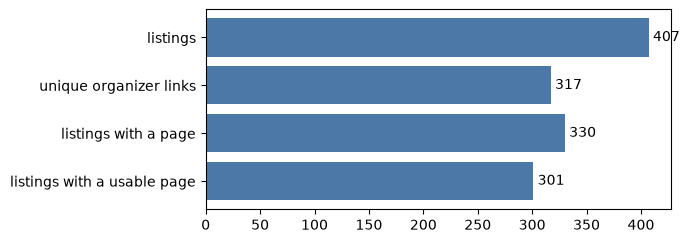

In [67]:
funnel = pd.Series({
    "listings": len(df),
    "unique organizer links": df["key"].nunique(),
    "listings with a page": int(df["has_page"].sum()),
    "listings with a usable page": int(df["page_usable"].sum()),
})
print(funnel.to_string())
print("\npages matching no listing:", int((~pages["key"].isin(listings["key"])).sum()))
print("page problems:", pages["problem"].value_counts(dropna=False).to_dict())
print("unique links still without a page:", df.loc[~df["has_page"], "key"].nunique())

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(funnel.index[::-1], funnel.values[::-1], color="#4c78a8")
for i, v in enumerate(funnel.values[::-1]): ax.text(v + 4, i, str(v), va="center")


So:

- "Listings with a page" (330) means a listing's organizer link was fetched and some text was saved for it. The notebook calculates it as has_page = page_text.notna(). It only checks that text exists, and it can be useless text.

- "Listings with a usable page" (301) is a stricter subset: the page also passes page_problem in clean.py. The notebook computes it as page_usable = has_page & problem.isna(). To recall: a page counts as unusable if it has any of these problems:

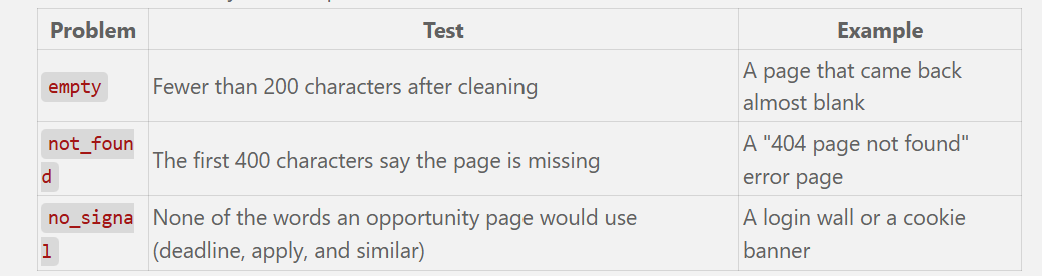

- As noticed above, 25 of the 251 fetched pages are not usable. (14 are "page not found", 7 have no listing words, and 4 are nearly empty.) But the gap is 29 listings and not 25: one page can serve several listings, so 25 bad pages remove 29 listings.

### EDA

We will check for:

1. Completeness (did it earlier too)
2. Label Balance --> Type
3. Text Length --> DeBERTa reads at most 512 tokens at a time. Words times about 1.3 is a rough token count
(the real tokenizer will be used later in Colab).
4. Time and Deadlines 
5. Duplicates --> Three kinds: the same organizer link used by several listings, the same title repeated across months (featured listings come back), and near-identical titles. Clusters use a link match plus a fairly similar title, or a very similar title on its own.
6. source of Noise
7. Analyze the content

title           0.0
description     0.2
deadline        1.7
fees           76.9
website         0.0
type            0.0


Text(0.5, 1.0, 'Field coverage by month')

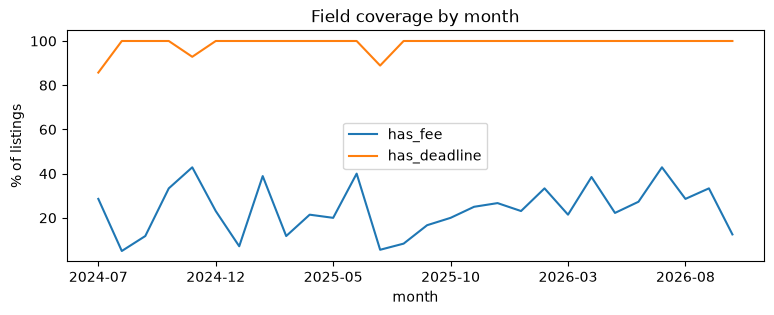

In [68]:
## Checking for missingness/Completeness of the data

cols = ["title", "description", "deadline", "fees", "website", "type"]
blank = df[cols].replace(r"^\s*$", np.nan, regex=True).isna().mean().mul(100).round(1) # explanation below
print(blank.to_string())

by_month = (df.assign(has_fee=df["fees"].notna(), has_deadline=df["deadline"].notna())
              .groupby("month")[["has_fee", "has_deadline"]].mean().mul(100))
# .assign(...) adds new columns to a copy of the table, without changing df
# here has_fee and has_deadline  are new columns
# the groupby operation then calculates the mean of these boolean columns for each month, then converted into %

fig, ax = plt.subplots(figsize=(9, 3))
by_month.plot(ax=ax); ax.set_ylabel("% of listings"); ax.set_title("Field coverage by month")

For finding the missing values in each column, we are first replacing any empty string or string with only whitespace with NaN (^ is the start of the text, \s* is any number of whitespace characters, including none, $ is the end of the text), then checking which columns have NaN values, calculating the mean (which gives us the proportion of NaN values), multiplying by 100 to get a percentage, and rounding to 1 decimal place. This gives us the 'percentage of listings' that have blank values for each of the specified columns.

- Fees has highest missing values - this might be a problem while training.
- Then Deadlines have second highest missing values, even though there are only 1.7%


type
Residency/Fellowship    181
Grant                   125
Open Call               101


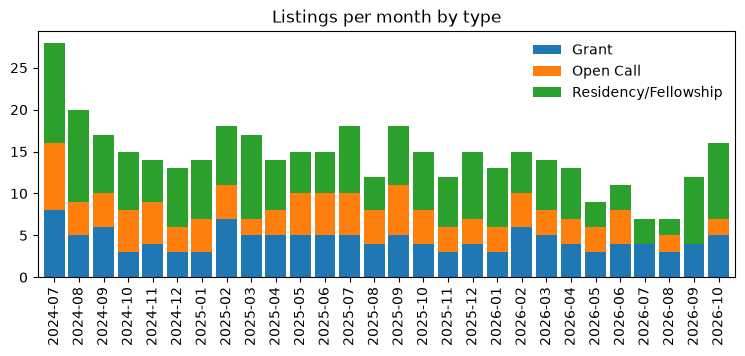

In [69]:
## Next, we will check the distribution of the type of listings, and the distribution of the number of listings per organizer (domain)

print(df["type"].value_counts().to_string())
ct = pd.crosstab(df["month"], df["type"])
# print(ct)
fig, ax = plt.subplots(figsize=(9, 3.2))
ct.plot.bar(stacked=True, ax=ax, width=0.85); ax.set_title("Listings per month by type"); ax.set_xlabel("")
ax.legend(frameon=False); # to remove the box around the legend
# save(fig, "type_by_month"); 
plt.show()

In [70]:
# checking ratio of residency/fellowship vs. rest for each month
print(df['type'].groupby(df['month']).value_counts(normalize=True))
ratio = df['type'].groupby(df['month']).value_counts(normalize=True).unstack(fill_value=0)
ratio.mul(100).round(1)
print("\nRatio of residency/fellowship vs. rest for each month (in %):")
print(ratio.mul(100).round(1).to_string())

month    type                
2024-07  Residency/Fellowship    0.428571
         Open Call               0.285714
         Grant                   0.285714
2024-08  Residency/Fellowship    0.550000
         Grant                   0.250000
                                   ...   
2026-09  Residency/Fellowship    0.666667
         Grant                   0.333333
2026-10  Residency/Fellowship    0.562500
         Grant                   0.312500
         Open Call               0.125000
Name: proportion, Length: 82, dtype: float64

Ratio of residency/fellowship vs. rest for each month (in %):
type     Grant  Open Call  Residency/Fellowship
month                                          
2024-07   28.6       28.6                  42.9
2024-08   25.0       20.0                  55.0
2024-09   35.3       23.5                  41.2
2024-10   20.0       33.3                  46.7
2024-11   28.6       35.7                  35.7
2024-12   23.1       23.1                  53.8
2025-01   21.4  

In [71]:
## shortcut:
ratio = pd.crosstab(df['month'], df['type'], normalize='index')
ratio.mul(100).round(1)


type,Grant,Open Call,Residency/Fellowship
month,,,
2024-07,28.6,28.6,42.9
2024-08,25.0,20.0,55.0
2024-09,35.3,23.5,41.2
2024-10,20.0,33.3,46.7
2024-11,28.6,35.7,35.7
2024-12,23.1,23.1,53.8
2025-01,21.4,28.6,50.0
2025-02,38.9,22.2,38.9
2025-03,29.4,11.8,58.8


Residencies/Fellowships are higher in number than the other two.

In [72]:
# listings per organizer (domain)
org_counts = df.groupby("domain").size()
org_counts.sort_values(ascending=False).head(10)

domain
jonathanandbarbarasilverfoundation.org    8
centerforcraft.org                        7
apexart.org                               7
foundwork.art                             6
arts.princeton.edu                        5
lbifoundation.org                         5
vilcek.org                                5
thebennettprize.org                       5
vermontstudiocenter.org                   5
morganconservatory.org                    4
dtype: int64

- Residency/Fellowship are highest type of opporunities
- I want Fellowship to go with Grants as they are close to each other <--> I haven't applied this categorization yet - will do this later

count      226.0
mean     10804.0
std      10894.0
min        268.0
25%       4028.0
50%       6980.0
75%      13778.0
max      65162.0

usable pages longer than 512 tokens (est.): 78%
median est. tokens: 1023  90th pct: 3202


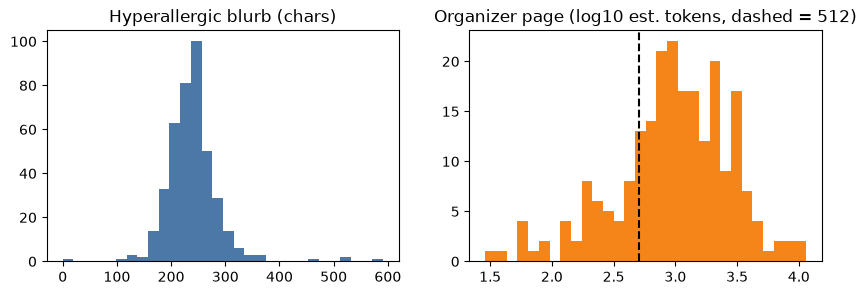

In [73]:
## Text Length - DeBERTa reads at most 512 tokens at a time. Words times about 1.3 is a rough token count

df["desc_chars"] = df["description"].str.len()
df["page_chars"] = df["page_text"].fillna("").str.len()
df["page_tokens_est"] = (df["page_text"].fillna("").str.split().str.len() * 1.3).round()

usable = df[df["page_usable"]].drop_duplicates("key")
print(usable["page_chars"].describe().round(0).to_string())
over = (usable["page_tokens_est"] > 512).mean()
print(f"\nusable pages longer than 512 tokens (est.): {over:.0%}")
print("median est. tokens:", int(usable["page_tokens_est"].median()), " 90th pct:", int(usable["page_tokens_est"].quantile(.9)))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(df["desc_chars"], bins=30, color="#4c78a8"); axes[0].set_title("Hyperallergic blurb (chars)")
axes[1].hist(np.log10(usable["page_tokens_est"].clip(lower=1)), bins=30, color="#f58518")
axes[1].axvline(np.log10(512), color="k", ls="--"); axes[1].set_title("Organizer page (log10 est. tokens, dashed = 512)")
plt.show()


- Blurbs are about 240 characters, too short to train on. Usable pages have a median of about 1,000 estimated tokens and 78% are longer than 512, so pages must be chunked.


In [74]:
## Time and Deadlines
# parse deadlines:

from datetime import date

def _iso(year, month, day):
    try:
        return date(year, month, day).isoformat()
    except ValueError:
        return None

_ROLLING = re.compile(r"\b(rolling|ongoing|open until filled|continuous(?:ly)?)\b", re.I)
_MONTH = r"(?:Jan(?:uary)?|Feb(?:ruary)?|Mar(?:ch)?|Apr(?:il)?|May|June?|July?|Aug(?:ust)?|Sept?(?:ember)?|Oct(?:ober)?|Nov(?:ember)?|Dec(?:ember)?)"
_DATE = re.compile(
    rf"(?P<m>{_MONTH})\.?\s+(?P<d>\d{{1,2}})(?:st|nd|rd|th)?"
    rf"(?:\s*[-–—]\s*(?:(?P<m2>{_MONTH})\.?\s+)?(?P<d2>\d{{1,2}}))?"
    r"(?:,?\s+(?P<y>\d{4}))?",
    re.I,
)

def parse_deadline(text, default_year=None):
    """Read a deadline string such as "February 1-March 1, 2025 (5pm EST)".

    Returns a dict with every date found (`dates`, ISO strings), the last one as
    `deadline` (for a range this is the end), and `is_rolling`. A date with no
    year takes the year of the next date that has one, or default_year (for
    example the year the listing was published). `deadline` is None when
    nothing could be read, and "TBD" style text gives no dates.
    """
    out = {"dates": [], "deadline": None, "is_rolling": False}
    if not isinstance(text, str) or not text.strip():
        return out
    out["is_rolling"] = bool(_ROLLING.search(text))
    found = []  # (month, day, year or None), in reading order
    for m in _DATE.finditer(text):
        y = int(m["y"]) if m["y"] else None
        m1 = MONTHS[m["m"][:3].lower()]
        if m["d2"]:
            m2 = MONTHS[m["m2"][:3].lower()] if m["m2"] else m1
            found += [(m1, int(m["d"]), None if y is None else y), (m2, int(m["d2"]), y)]
        else:
            found.append((m1, int(m["d"]), y))
    # a date without a year borrows from the next one that has a year
    next_year = default_year
    for i in range(len(found) - 1, -1, -1):
        mo, d, y = found[i]
        if y is None:
            y = next_year
        else:
            next_year = y
        found[i] = (mo, d, y)
    out["dates"] = [iso for mo, d, y in found if y and (iso := _iso(y, mo, d))]
    out["deadline"] = out["dates"][-1] if out["dates"] else None
    return out

deadline missing: 7  could not parse: 0
more than one date: 14  rolling: 2
deadline already past (as of 2026-10-07): 381 of 400
count    400.0
mean      34.0
std       38.0
min     -335.0
25%       20.0
50%       30.0
75%       45.0
max      155.0
deadline before the post was published: 3


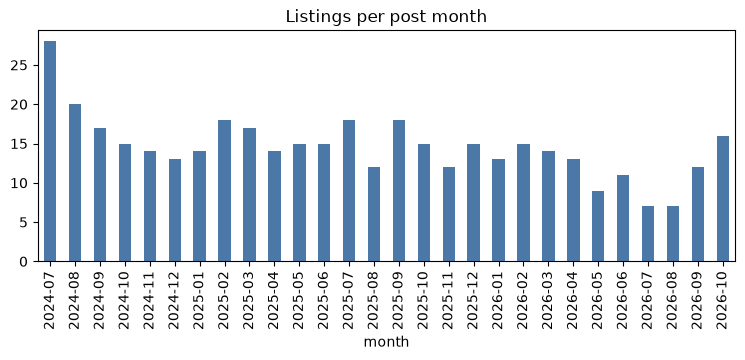

In [75]:
## Time and Deadlines

pub_year = df["published_at"].dt.year
dl = [parse_deadline(s, default_year=y) for s, y in zip(df["deadline"], pub_year)]
df["deadline_iso"] = [d["deadline"] for d in dl]
df["n_dates"] = [len(d["dates"]) for d in dl]
df["is_rolling"] = [d["is_rolling"] for d in dl]
df["deadline_dt"] = pd.to_datetime(df["deadline_iso"])
today = pd.Timestamp("2026-10-07")

print("deadline missing:", int(df["deadline"].isna().sum()), " could not parse:", int((df["deadline"].notna() & df["deadline_iso"].isna()).sum()))
print("more than one date:", int((df["n_dates"] > 1).sum()), " rolling:", int(df["is_rolling"].sum()))
print("deadline already past (as of 2026-10-07):", int((df["deadline_dt"] < today).sum()), "of", int(df["deadline_dt"].notna().sum()))
df["days_notice"] = (df["deadline_dt"] - df["published_at"].dt.tz_localize(None)).dt.days
print(df["days_notice"].describe().round(0).to_string())
print("deadline before the post was published:", int((df["days_notice"] < 0).sum()))
df.loc[df["days_notice"] < 0, ["month", "title", "deadline", "deadline_iso"]]

fig, ax = plt.subplots(figsize=(9, 3))
df["month"].value_counts().sort_index().plot.bar(ax=ax, color="#4c78a8"); ax.set_title("Listings per post month")
plt.show()

In [76]:
## Duplicates
'''
Three kinds: the same organizer link used by several listings, the same title repeated across months (featured listings come back), and near-identical titles. Clusters use a link match plus a fairly similar title, or a very similar title on its own. 
'''

from rapidfuzz import process, fuzz

t = df["title"].map(normalize_text).str.lower().tolist()
sim = process.cdist(t, t, scorer=fuzz.token_set_ratio, workers=-1)
n = len(df)
keys = df["key"].to_numpy(dtype=object)
same_key = keys[:, None] == keys[None, :]
link = same_key & (sim >= 80)
dup = link | (sim >= 92)
np.fill_diagonal(dup, False)

parent = list(range(n))
def find(i):
    while parent[i] != i: parent[i] = parent[parent[i]]; i = parent[i]
    return i
for i, j in zip(*np.where(np.triu(dup))): parent[find(i)] = find(j)
df["cluster"] = [find(i) for i in range(n)]

print("exact title repeats:", int(df["title"].duplicated().sum()))
print("same link used by >1 listing:", int(df["key"].duplicated().sum()), "extra rows")
print("clusters (estimated distinct opportunities):", df["cluster"].nunique(), "from", n, "rows")
sizes = df["cluster"].value_counts()
print("cluster size counts:", sizes.value_counts().sort_index().to_dict())

# Same link but NOT merged: probably different calls on one page (e.g. apexart's open calls page)
shared = df[df["key"].duplicated(keep=False)].groupby("key")["cluster"].nunique()
print("links used by several listings that stay separate clusters:", int((shared > 1).sum()))
df.loc[df["cluster"].isin(sizes[sizes > 1].index)].sort_values(["cluster", "month"])[["cluster", "month", "title", "deadline"]].head(25)

exact title repeats: 66
same link used by >1 listing: 90 extra rows
clusters (estimated distinct opportunities): 285 from 407 rows
cluster size counts: {1: 212, 2: 45, 3: 18, 4: 5, 5: 2, 6: 1, 7: 1, 8: 1}
links used by several listings that stay separate clusters: 4


,cluster,month,title,deadline
23,23,2026-09,American-Scandinavian Foundation: Fellowships for Americans – 2026/2027 Award Cycle,"November 1, 2026"
10,23,2026-10,American-Scandinavian Foundation: Fellowships for Americans – 2026/2027 Award Cycle,"November 1, 2026"
49,49,2026-06,Hyundai Motor Group – The 7th VH Award,"July 21, 2026"
40,49,2026-07,Hyundai Motor Group – The 7th VH Award,"July 21, 2026"
55,55,2026-05,Provincetown Art Association and Museum - Robert Motherwell & Renate Ponsold Fellowship,"June 1, 2026"
12,55,2026-10,Provincetown Art Association and Museum — Robert Motherwell & Renate Ponsold Fellowship,"November 2, 2026"
102,102,2026-02,The Vilcek Foundation – 2026 Open Call for Grants,"April 30, 2026"
84,102,2026-03,The Vilcek Foundation – 2026 Open Call for Grants,"April 30, 2026"
71,102,2026-04,The Vilcek Foundation – 2026 Open Call for Grants,"April 30, 2026"
145,145,2025-10,A.I.R. Gallery – Fellowship for Emerging and Underrepresented Women and Non-Binary Artists,"November 7, 2025"


- Merging by link plus a similar title, or a very similar title, gives 285 clusters. A cluster can hold different years of one program (for example A.I.R. Gallery 2025 and 2026), so need to decide whether the newest cycle or all cycles are kept. 
- **Splits must be by cluster (and ideally by organizer) to avoid leakage.**

In [77]:
## Noise

allcols = df[["title", "description", "page_text"]].fillna("")
noise = {
    "non-breaking space": allcols.apply(lambda c: c.str.contains("\u00a0")).sum(),
    "zero-width char": allcols.apply(lambda c: c.str.contains("[\u200b-\u200d\ufeff]")).sum(),
    "curly quotes": allcols.apply(lambda c: c.str.contains("[\u2018\u2019\u201c\u201d]")).sum(),
    "replacement char": allcols.apply(lambda c: c.str.contains("\ufffd")).sum(),
}
print(pd.DataFrame(noise).T.to_string())
print("\ntitle > 140 chars:", int((df["title"].str.len() > 140).sum()), " empty description:", int((df["description"].str.len() == 0).sum()))
print("\nunusable pages:")
bad = pages[pages["problem"].notna()]
for _, r in bad.head(8).iterrows():
    print(f"  [{r['problem']}] {r['source_url'][:70]} | {ascii(r['raw_text'][:70]) if isinstance(r['raw_text'], str) else None}")

                    title  description  page_text
non-breaking space     17           27        163
zero-width char         0            1         27
curly quotes           10           92        260
replacement char        0            0          0

title > 140 chars: 1  empty description: 1

unusable pages:
  [not_found] https://www.curatorialprogram.org/hello-ny-brooklyn | '[CPR \u2014 home](https://curatorialprogram.org/)\n\n[Support CPR](https://cu'
  [not_found] https://www.ephemere.tokyo/grants | "[0](https://www.ephemere.tokyo/cart)\n\nWe couldn't find the page you we"
  [not_found] https://www.lbifoundation.org/callforartists | '[Skip to content](https://lbifoundation.org/callforartists#jupiterx-ma'
  [empty] https://longmeadowartresidency.com/apply | '403\n\nResidency applications are not open at this time.'
  [not_found] https://www.tate.org.uk/research/tate-papers/call-for-papers-whistlers | "# Page not found\n\nSorry, we can't find the page you're looking for.\n\nY"
  [no_

- Deadline: 7 missing, every other one parses. 14 contain more than one date, 2 are rolling. 3 deadlines fall before the post date; these are year typos in the source.
- Fees: 77% blank (blank means not mentioned). Of the 94 present, 76 are application fees and 18 are something else (artist fees, workshop or program fees). The scraper's "fee" keyword match is noisy, so do not trust `fees` as a label without checking.
- Fee amounts are mostly $10 to $50. Two fees are in pounds or euros.
- Real noise is small: non-breaking spaces (163 pages), zero-width characters (27 pages), curly quotes. No broken encoding. The `?` symbols seen in a Windows terminal are just display.

**Content Analysis**: An important thing to check is: if a listing's deadline or fee also appears as text in the organizer page, we can use it to create labels automatically later.

In [78]:
def parse_fees(text):
    """Read a fee sentence such as "Application fees are $35-40."
    `fee_mentioned` is False for an empty value, which means the listing did
    not say, not that it is free. Amounts are the smallest and largest numbers
    found. `fee_is_application` separates application fees from other costs
    such as workshop or program fees.
    """
    out = {"fee_mentioned": False, "fee_min": None, "fee_max": None, "fee_currency": None, "fee_is_application": None}
    if not isinstance(text, str) or not text.strip():
        return out
    out["fee_mentioned"] = True
    amounts, currency = [], None
    for m in _AMOUNT.finditer(text):
        currency = currency or m["cur"]
        for g in ("lo", "hi"):
            if m[g]:
                amounts.append(float(m[g].replace(",", "")))
    if amounts:
        out["fee_min"], out["fee_max"], out["fee_currency"] = min(amounts), max(amounts), currency
    out["fee_is_application"] = bool(_APPLICATION_FEE.search(text))
    return out

deadline found in page text: 0.37 of 294 checked
                            mean  count
deadline_since_2026-09                 
False                   0.329588    267
True                    0.740741     27

fee text present: 94  with an amount: 88  application fees: 76
fee text that is not an application fee (artist fees, workshop fees...): 18
currencies: {'$': 86, '€': 2}
application fee amount found in page text: 0.38 of 55 checked


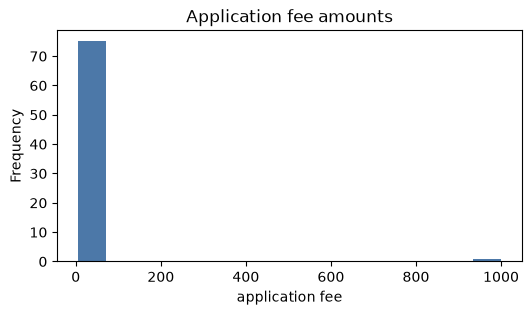

In [79]:
_AMOUNT = re.compile(
    r"(?P<cur>[$£€])\s?(?P<lo>\d[\d,]*(?:\.\d+)?)"
    r"(?:\s*[-–—]\s*[$£€]?\s?(?P<hi>\d[\d,]*(?:\.\d+)?))?"
)
_APPLICATION_FEE = re.compile(r"\b(application|apply|entry|submission|submit)\b", re.I)


def deadline_in_page(row):
    if not (row["page_usable"] and pd.notna(row["deadline_iso"])): return np.nan
    d = pd.Timestamp(row["deadline_iso"])
    pat = rf"\b{d.strftime('%b')}[a-z]*\.?\s+0?{d.day}(?:st|nd|rd|th)?\b|\b0?{d.day}(?:st|nd|rd|th)?\s+(?:of\s+)?{d.strftime('%b')}"
    return bool(re.search(pat, row["page_text"], re.I))

df["deadline_in_page"] = df.apply(deadline_in_page, axis=1)

print("deadline found in page text:", df["deadline_in_page"].dropna().mean().round(2), "of", int(df["deadline_in_page"].notna().sum()), "checked")

# pages were fetched in Oct 2026, so a page for an old listing usually shows the next cycle's dates
upcoming = df["deadline_dt"] >= pd.Timestamp("2026-09-01")
print(df.groupby(upcoming.rename("deadline_since_2026-09"))["deadline_in_page"].agg(["mean", "count"]).round(2).to_string())

fees = df["fees"].map(parse_fees).apply(pd.Series)
df = df.join(fees)
## if want to re-run this cell without errors then use:
# fees = df["fees"].map(parse_fees).apply(pd.Series)
# df = df.drop(columns=fees.columns, errors="ignore").join(fees)


print("\nfee text present:", int(df["fee_mentioned"].sum()), " with an amount:", int(df["fee_min"].notna().sum()),
      " application fees:", int(df["fee_is_application"].fillna(False).sum()))
print("fee text that is not an application fee (artist fees, workshop fees...):",
      int((df["fee_mentioned"] & ~df["fee_is_application"].fillna(False).astype(bool)).sum()))
print("currencies:", df["fee_currency"].value_counts().to_dict())

def fee_in_page(row):
    if not (row["page_usable"] and row["fee_is_application"] and pd.notna(row["fee_min"])): return np.nan
    amt = f"{int(row['fee_min']):,}"
    return bool(re.search(rf"[$\u00a3\u20ac]\s?{amt}\b", row["page_text"]))
df["fee_in_page"] = df.apply(fee_in_page, axis=1)
print("application fee amount found in page text:", df["fee_in_page"].dropna().mean().round(2), "of", int(df["fee_in_page"].notna().sum()), "checked")

fig, ax = plt.subplots(figsize=(6, 3))
df.loc[df["fee_is_application"] == True, "fee_min"].plot.hist(bins=15, ax=ax, color="#4c78a8")
ax.set_xlabel("application fee")
ax.set_title("Application fee amounts")
plt.show()

- Only 37% of deadlines and 38% of application fees can be found in the page text.
- The cause is timing: pages were fetched in Oct 2026, and 381 of 400 listing deadlines are already past, so pages show the next cycle's dates. For deadlines since Sept 2026 the match rate is 74%. Use recent listings for automatic labels, and expect to hand label the rest.

Lastly, Out of scope currently means non-U.S. or not a grant, open call, or residency. We will flag them only - nothing is dropped.


In [80]:
## Flags

NON_US = r"\b(?:canada|canadian|toronto|montreal|vancouver|banff|uk|united kingdom|england|london|scotland|ireland|dublin|berlin|germany|paris|france|italy|rome|venice|spain|athens|greece|netherlands|amsterdam|sweden|norway|denmark|finland|iceland|japan|tokyo|korea|china|india|australia|mexico|brazil|argentina|africa|europe|european|asia|international)\b"

text = (df["title"] + " " + df["description"]).fillna("")

df["flag_non_us"] = text.str.contains(NON_US, case=False, regex=True) | df["fee_currency"].isin(["\u00a3", "\u20ac"])

df["flag_not_target_type"] = text.str.contains(r"\b(?:workshop|clinic|conference|festival|commission|art fair|job|hiring|position)\b", case=False, regex=True)

print("non-US flag:", int(df["flag_non_us"].sum()), " odd-type flag:", int(df["flag_not_target_type"].sum()))

print(df.groupby("type")[["flag_non_us", "flag_not_target_type"]].sum().to_string())

df.loc[df["flag_not_target_type"], ["month", "type", "title"]].head(12)

non-US flag: 35  odd-type flag: 27
                      flag_non_us  flag_not_target_type
type                                                   
Grant                          14                     3
Open Call                      12                    14
Residency/Fellowship            9                    10


,month,type,title
0,2026-10,Grant,ArtFields — 2027 Festival Call for Artists
48,2026-06,Open Call,National Council on Education for the Ceramic Arts (NCECA) – Open Call for Exhibitions
69,2026-04,Open Call,Art in Odd Places 2026: UTOPIAS - Open Call for Proposals
78,2026-03,Residency/Fellowship,University of Rochester Department of Art & Art History – Fanny Knapp Allen Artist in Residence
110,2026-01,Residency/Fellowship,The Morgan Conservatory – Certificate in Professional Papermaking
126,2025-12,Open Call,Museum of the Moving Image – 2025 Marvels of Media Festival
139,2025-11,Open Call,National Trust – Sycamore Gap Anniversary Commission
146,2025-10,Residency/Fellowship,at Louis Place – Artist Publishing Cohort
152,2025-10,Open Call,"San Bruno, California – Open Call for Sculpture at Posy Park"
155,2025-10,Grant,2026 ArtFields Festival


- 35 listings are flagged non-U.S. and 27 as an odd type (festival, workshop, commission, job). Flags only, nothing dropped. Need to check a sample of keywords by hand.

## Summary of observations

**Data**
- 407 listings from 29 Hyperallergic posts (July 2024 to October 2026) and 251 organizer pages.
- July 2024 is in twice (two posts with 14 listings each), so that month is doubled until duplicates are merged.

**Completeness**
- `fees` is blank for 77% of listings (313), `deadline` for 1.7% (7), and `description` for 1. Every other column is complete.
- A blank fee means no "fee" keyword was found. It does not mean the listing is free.
- `published_at` is filled in for only 15 of the 251 pages, so use the listing's own date for time analysis.

**Organizer pages**
- 25 of 251 pages are not usable text: 14 "page not found", 7 with no listing words (login walls, banners), 4 nearly empty. That leaves 226 usable pages.
- 330 listings have a page and 301 have a usable one. The gap is 29, not 25, because one page can serve several listings.

**Type balance**
- Residency/Fellowship is the largest type (181), then Grant (125) and Open Call (101).
- Residency/Fellowship has the biggest share in most months (typically 40 to 55%). Grant leads in 2026-06, 2026-07, and 2026-08.
- A month has only 7 to 20 listings, so the shares swing a lot.
- Fellowships should go with grants. This is decided but not yet applied.
- Some organizers repeat a lot: the Silver Foundation (8), Center for Craft (7), apexart (7), Foundwork (6).

**Text length**
- Hyperallergic blurbs are about 240 characters, too short to train on.
- Usable pages have a median of about 6,980 characters (about 1,023 estimated tokens, 90th percentile 3,202).
- 78% are longer than 512 tokens, so pages must be split into chunks.

**Time and deadlines**
- 7 deadlines are missing. Every other one parses. 14 contain more than one date, and 2 are rolling.
- 381 of 400 deadlines were already past on October 7, 2026.
- The median notice between the post and the deadline is 30 days (25% at 20 days, 75% at 45, longest 155).
- 3 deadlines fall before the post date. These are year typos in the source.

**Duplicates**
- 66 titles repeat exactly, and 90 extra rows share a link with another listing.
- Merging by link and a similar title, or a very similar title, gives 285 clusters from 407 rows (212 appear once).
- A cluster can hold different years of one program (for example A.I.R. Gallery 2025 and 2026), so decide whether to keep the newest cycle or all cycles.
- 4 links are shared by listings that stay in separate clusters, for example apexart's open calls page.

**Noise**
- Real noise is small: non-breaking spaces, zero-width characters, and curly quotes. No replacement characters or broken encoding.
- The cleaner does not yet remove the soft hyphen (U+00AD), the word joiner (U+2060), or unusual spaces (U+202F, U+2009, hair space).
- 1 title is over 140 characters, and 1 description is empty.

**Content analysis (does the listing's data appear in the organizer page?)**
- Only 37% of deadlines (294 checked) are found in the page text.
- The cause is timing: pages were fetched in October 2026, so a page for an old listing usually shows the next cycle's dates. For deadlines since September 2026 the match is 74% (27 listings), against 33% for older ones (267).
- Fees: 94 listings have fee text, 88 have an amount, 76 are application fees, and 18 are other costs (artist, workshop, program fees). Amounts are mostly $10 to $50, and 2 are in another currency.
- Only 38% of application fee amounts (55 checked) are found in the page text.
- The "fee" keyword match is noisy, so `fees` should not be used as a label without checking.

**Scope flags**
- 35 listings look non-U.S. and 27 look like an odd type (festival, workshop, commission, job). Nothing is dropped.
- The keyword lists are rough, so check a sample by hand.

**What this means**
- Split train and test by organizer and by cluster, to avoid leakage.
- Use only usable pages, and split them into chunks for the model.
- Clean the text once, before labeling.
- Use recent listings for automatic labels, and expect to hand label the rest.

# Preprocessing 

(writes to `data/clean/`)

In the EDA section above we *identified* the problems. Now we fix them and write the files that would be useful for later stages such as training etc. The order matters, and following are the steps:

1. **Text normalization**: fix encoding and odd characters, **and keep an offset map** so a label placed on the clean text can be traced back to the raw text.
2. **Page cleaning**: drop empty, error and boilerplate pages/lines. The original text is always kept next to the cleaned text.
3. **Field normalization**: `deadline` to ISO dates, `fees` to numbers, `type` to the three project categories.
4. **Deduplication**: one canonical record per real opportunity. This is done *before* any split, otherwise the same listing could land in both train and test.
5. **Merge**: attach the page text to each listing.
6. **Chunking**: cut long pages into overlapping windows that fit the model.
7. **Split**: train/val/test by organizer, with a fixed seed.
8. **Outputs**: `listings.jsonl`, `chunks.jsonl`, `splits.json`, `data_report.md`.

Throughout, a dictionary called `drops` records everything we remove and why, so the final report is generated from real numbers instead of written by hand.

In [81]:
# Setup: extra imports, the output folder, and the "drops" log used by the final report.
import bisect, difflib, hashlib, json, random
import dateparser

CLEAN_DIR = ROOT / "data" / "clean"          # ROOT was defined near the top of the notebook
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42                                    # one seed for everything random below

drops = {}   # name -> (count, reason). Filled in as we go, printed in data_report.md at the end.

### 1. Text normalization (with an offset map)

`normalize_text` defined above in this notebook (also in `preprocess/clean.py`) already fixes broken encodings (`ftfy`), non-breaking spaces, zero-width characters and runs of whitespace. The EDA found a few things it does **not** handle, so we add them in `normalize_for_model`:

- **Unicode NFKC**: folds look-alike characters (ligatures like `ﬁ`, full-width letters, `…` to `...`) into plain ones.
- **Soft hyphen (U+00AD) and word joiner (U+2060)**: invisible, listed in the EDA summary as not yet handled.
- **Curly quotes to straight quotes**: so `don’t` and `don't` are the same string for the model and for label matching. En/em dashes are kept.

**Why the offset map?**: Labels are character positions (`start`, `end`) on the *clean* text. If we ever need to show the annotator the original, or check a label against the source page, we must be able to translate a clean position back to a raw position (without a map, we'd lose the link back to the source). Every edit above shifts characters, so we cannot just subtract a constant. Cleaning changes characters: \xa0 becomes a space, ’ becomes ', soft hyphens and zero-width characters vanish, blank lines collapse, and boilerplate lines are deleted. After that, character 500 in the clean page is no longer character 500 in the raw page. 

How the map works: we compare raw and clean with `difflib`, and keep every stretch of characters that survived (or was swapped 1-for-1, like a curly quote). Each stretch is stored as `[clean_start, raw_start, length]`. A position inside a stretch converts exactly; a position inside a deleted/rewritten area snaps to the nearest kept character.

In [82]:
_QUOTES = {ord(c): "'" for c in "\u2018\u2019\u201a\u201b\u2032"} | {ord(c): '"' for c in "\u201c\u201d\u201e\u201f\u2033"}

def normalize_for_model(text):
    """Full text normalization used for everything the model will read.

    Order matters: ftfy first (it repairs mojibake, which later steps would make permanent),
    then NFKC, then removal of invisible characters, then quotes, then a last whitespace tidy.
    """
    text = normalize_text(text)                       # ftfy + NFC + nbsp + zero-width + whitespace
    text = unicodedata.normalize("NFKC", text)        # ligatures, full-width forms, unusual spaces
    text = re.sub("[\u00ad\u2060]", "", text)         # soft hyphen, word joiner
    text = text.translate(_QUOTES)                    # curly -> straight quotes
    return normalize_text(re.sub(r"[ \t]+", " ", text))


def _char_segments(raw, clean, raw_off, clean_off):
    """Character-level diff of two short strings. Yields [clean_start, raw_start, length] stretches."""
    sm = difflib.SequenceMatcher(None, raw, clean, autojunk=False)
    for op, i1, i2, j1, j2 in sm.get_opcodes():
        if j2 > j1 and (op == "equal" or (op == "replace" and i2 - i1 == j2 - j1)):
            yield [clean_off + j1, raw_off + i1, j2 - j1]


def build_offset_map(raw, clean):
    """Describe which stretches of `clean` come from which stretch of `raw`.

    Returns a list of [clean_start, raw_start, length]. Equal stretches and 1-for-1 swaps
    (e.g. a curly quote becoming a straight one) are kept; deletions and rewrites are gaps.

    A character-level diff of a whole page is slow (it grows with the square of the length), so we
    first diff line by line, which pins down the unchanged lines at once, and only run the
    character-level diff inside the few lines that actually changed.
    """
    rl, cl = raw.split("\n"), clean.split("\n")
    r_off = np.cumsum([0] + [len(x) + 1 for x in rl])      # start of each line in raw
    c_off = np.cumsum([0] + [len(x) + 1 for x in cl])      # start of each line in clean
    found = []
    for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, rl, cl, autojunk=False).get_opcodes():
        rb, cb = "\n".join(rl[i1:i2]), "\n".join(cl[j1:j2])
        if op == "equal":
            found.append([int(c_off[j1]), int(r_off[i1]), len(cb)])
        elif rb and cb:
            found += [[int(a), int(b), n] for a, b, n in _char_segments(rb, cb, r_off[i1], c_off[j1])]
    segs = []
    for s in found:                                         # glue stretches that touch
        if segs and segs[-1][0] + segs[-1][2] == s[0] and segs[-1][1] + segs[-1][2] == s[1]:
            segs[-1][2] += s[2]
        else:
            segs.append(s)
    return segs


def clean_to_raw_span(segs, start, end, raw_len):
    """Turn a [start, end) span on the clean text into a [start, end) span on the raw text."""
    starts = [s[0] for s in segs]

    def locate(pos):                                   # index of the stretch holding clean position `pos`
        i = bisect.bisect_right(starts, pos) - 1
        return i, (i >= 0 and pos < segs[i][0] + segs[i][2])

    i, inside = locate(start)
    if inside:
        raw_start = segs[i][1] + start - segs[i][0]
    else:                                              # start sits in a gap: use the next kept character
        raw_start = segs[i + 1][1] if i + 1 < len(segs) else raw_len
    i, inside = locate(end - 1)
    if inside:
        raw_end = segs[i][1] + (end - 1) - segs[i][0] + 1
    else:                                              # end sits in a gap: use the end of the last kept stretch
        raw_end = segs[i][1] + segs[i][2] if i >= 0 else 0
    return raw_start, max(raw_end, raw_start)


# Quick demonstration on a made-up string
demo_raw = "Artists\u00a0can\u2019t apply\u200b  after\n\n\n\nMay\u00ad 1"
demo_clean = normalize_for_model(demo_raw)
print('\n')
demo_segs = build_offset_map(demo_raw, demo_clean)
print('\n', repr(demo_clean), demo_segs)
s, e = clean_to_raw_span(demo_segs, demo_clean.index("can't"), demo_clean.index("can't") + 5, len(demo_raw))
print("clean 'can't' -> raw span", (s, e), repr(demo_raw[s:e]))




 "Artists can't apply after\n\nMay 1" [[0, 0, 19], [19, 21, 6], [26, 28, 0], [27, 31, 3], [30, 35, 2]]
clean 'can't' -> raw span (8, 13) 'can’t'


### 2. Page cleaning

We build one cleaned record per organizer page, keeping the original next to it.

Two layers of cleaning:

1. **Whole-page drops.** After normalizing, a page is dropped (its text becomes empty and `page_problem` says why) if it is `empty`, `not_found` or `no_signal`. These are the same rules as in the EDA's `page_problem`, but now applied to the *normalized* text, since removing boilerplate can leave a page empty.
2. **Boilerplate lines.** Navigation, cookie banners and footers are short lines such as `Accept all cookies`, `Privacy Policy`, `© 2026 ...`, `Menu`. We remove a line only if it is **short (at most 100 characters)** and matches a boilerplate pattern, so a real sentence that merely mentions "newsletter" is safe.

Offsets are computed once, from the *original* page to the *final* cleaned page (both steps combined), so a single map covers everything.

In [83]:
_BOILER = re.compile(
    r"cookie|accept (?:all|cookies)|privacy (?:policy|settings|notice)|terms (?:of|&|and) (?:use|service)|"
    r"all rights reserved|skip to (?:main )?content|subscribe|newsletter|follow us|back to top|"
    r"toggle (?:navigation|menu)|\u00a9|\bcopyright\b|powered by|website by|site by", re.I)
_NAV_WORDS = {"menu", "home", "about", "contact", "search", "close", "login", "log in", "donate", "shop",
              "cart", "news", "events", "press", "support us", "skip to content"}


def strip_boilerplate(text):
    """Remove short nav / cookie / footer lines. Returns (text, number_of_lines_removed)."""
    kept, removed = [], 0
    for line in text.split("\n"):
        s = line.strip()
        if s and len(s) <= 100 and (_BOILER.search(s) or s.lower() in _NAV_WORDS):
            removed += 1
            continue
        kept.append(line)
    return re.sub(r"\n{3,}", "\n\n", "\n".join(kept)).strip(), removed


# one row per organizer link; if the same link was fetched twice keep the latest fetch
pg = pages.sort_values("scraped_at").drop_duplicates("key", keep="last").copy()
drops["duplicate page fetches"] = (len(pages) - len(pg), "same organizer link fetched more than once; latest kept")

recs = []
for _, r in pg.iterrows():
    raw = r["raw_text"] if isinstance(r["raw_text"], str) else ""
    clean, n_boiler = strip_boilerplate(normalize_for_model(raw))
    problem = page_problem(clean)                      # empty / not_found / no_signal / None
    recs.append({
        "key": r["key"],
        "page_text_raw": raw,                          # the untouched source, never overwritten
        "page_text": clean if problem is None else None,
        "page_problem": problem,
        "boilerplate_lines_removed": n_boiler,
        "page_offsets": build_offset_map(raw, clean) if problem is None else None,
    })
pg = pd.DataFrame(recs)

print("pages:", len(pg), "| usable after cleaning:", int(pg["page_text"].notna().sum()))
print(pg["page_problem"].value_counts(dropna=False).to_string())
print("boilerplate lines removed:", int(pg["boilerplate_lines_removed"].sum()),
      "from", int((pg["boilerplate_lines_removed"] > 0).sum()), "pages")

for p, n in pg["page_problem"].value_counts().items():
    drops[f"pages dropped: {p}"] = (int(n), {"empty": "almost no text", "not_found": "error / page-not-found",
                                             "no_signal": "no opportunity words (login wall, banner)"}[p])
drops["boilerplate lines removed"] = (int(pg["boilerplate_lines_removed"].sum()), "short nav / cookie / footer lines")

# Safety check on the offset map: take random words from the clean text, map them back to the raw text,
# and confirm that normalizing the raw span gives the same word again.
random.seed(SEED)
ok = tot = 0
for _, r in pg[pg["page_text"].notna()].iterrows():
    words = list(re.finditer(r"\S+", r["page_text"]))
    for m in random.sample(words, min(30, len(words))):
        s, e = clean_to_raw_span(r["page_offsets"], m.start(), m.end(), len(r["page_text_raw"]))
        ok += normalize_for_model(r["page_text_raw"][s:e]) == m.group(); tot += 1
print(f"offset map round-trip: {ok}/{tot} = {ok/tot:.1%}")
assert ok / tot > 0.97

pages: 251 | usable after cleaning: 226
page_problem
NaN          226
not_found     13
no_signal      7
empty          5
boilerplate lines removed: 368 from 127 pages
offset map round-trip: 6719/6758 = 99.4%


### 3. Field normalization

Starting again from the raw `listings` table (so earlier EDA columns don't leak in), we normalize the text columns and then three structured fields. The raw values are kept in `*_raw` columns.

- **`deadline`**: `parse_deadline` reads the date(s) (for a range, the end date is the deadline). Anything it cannot read falls back to `dateparser`. We add `is_rolling` and `deadline_suspect` (the deadline is *before* the post date, which the EDA found are year typos). Suspect deadlines are flagged, **not** edited, because guessing the right year would invent data.
- **`fees`**: `parse_fees` gives `fee_min`, `fee_max`, `fee_currency`, `fee_mentioned`. A blank fee means *not mentioned*, never "free". Text like "No fee" is flagged separately as `fee_free`.
- **`type`**: the scraper has `Residency/Fellowship`, `Grant`, `Open Call`. The project uses three categories where fellowships go with grants (decided in the EDA), so we split the combined label: a `Residency/Fellowship` row that talks about a *fellowship* and not a *residency* becomes `Grant/Fellowship`; the rest become `Residency`. Result: **`Residency`, `Grant/Fellowship`, `Open Call`**.

In [84]:
L = listings.copy()
for col in ["title", "description", "deadline", "fees"]:
    L[f"{col}_raw"] = L[col]
    L[col] = L[col].map(lambda t: normalize_for_model(t) if isinstance(t, str) else None)
    L.loc[L[col] == "", col] = None                    # empty string -> proper missing value

L["key"] = L["website"].map(url_key)
L["domain"] = L["website"].map(domain)
L["month"] = L["source_url"].map(month_from_source_url)

# ---------- deadline ----------
dl = [parse_deadline(s, default_year=y) for s, y in zip(L["deadline"], L["published_at"].dt.year)]
L["deadline_iso"] = [d["deadline"] for d in dl]
L["deadline_dates"] = [d["dates"] for d in dl]         # every date found (ranges, multiple rounds)
L["is_rolling"] = [d["is_rolling"] for d in dl]
L["deadline_source"] = np.where(L["deadline_iso"].notna(), "regex", None)

# fallback: let dateparser try the strings our regex could not read (skip rolling / TBD-like text)
need = L["deadline"].notna() & L["deadline_iso"].isna() & ~L["is_rolling"]
for i in L.index[need]:
    parsed = dateparser.parse(L.at[i, "deadline"], settings={"PREFER_DATES_FROM": "future",
                                                             "RELATIVE_BASE": L.at[i, "published_at"].to_pydatetime().replace(tzinfo=None)})
    if parsed:
        L.at[i, "deadline_iso"] = parsed.date().isoformat()
        L.at[i, "deadline_dates"] = [L.at[i, "deadline_iso"]]
        L.at[i, "deadline_source"] = "dateparser"

L["deadline_suspect"] = pd.to_datetime(L["deadline_iso"]) < L["published_at"].dt.tz_localize(None).dt.normalize()

# ---------- fees ----------
fee_cols = ["fee_mentioned", "fee_min", "fee_max", "fee_currency", "fee_is_application"]
L = L.join(L["fees"].map(parse_fees).apply(pd.Series)[fee_cols])
L["fee_free"] = L["fees"].fillna("").str.contains(r"\b(?:no fees?|free|no charge|no cost)\b", case=False, regex=True)

# ---------- type -> three project categories ----------
def project_type(row):
    if row["type"] == "Grant":
        return "Grant/Fellowship"
    if row["type"] == "Open Call":
        return "Open Call"
    text = f"{row['title'] or ''} {row['description'] or ''}"
    if re.search(r"fellowship", text, re.I) and not re.search(r"residen", text, re.I):
        return "Grant/Fellowship"
    return "Residency"

L["type_raw"] = L["type"]
L["type"] = L.apply(project_type, axis=1)

print("deadline: missing", int(L["deadline"].isna().sum()), "| unparsed", int((L["deadline"].notna() & L["deadline_iso"].isna()).sum()),
      "| dateparser fallback", int((L["deadline_source"] == "dateparser").sum()),
      "| rolling", int(L["is_rolling"].sum()), "| suspect (before post date)", int(L["deadline_suspect"].sum()))
print("fees: mentioned", int(L["fee_mentioned"].sum()), "| with amount", int(L["fee_min"].notna().sum()), "| 'free' wording", int(L["fee_free"].sum()))
print(pd.crosstab(L["type_raw"], L["type"]).to_string())

deadline: missing 7 | unparsed 0 | dateparser fallback 0 | rolling 2 | suspect (before post date) 3
fees: mentioned 94 | with amount 88 | 'free' wording 4
type                  Grant/Fellowship  Open Call  Residency
type_raw                                                    
Grant                              125          0          0
Open Call                            0        101          0
Residency/Fellowship                58          0        123


### 4. Deduplication (before any split)

The EDA found that the same opportunity shows up several times: featured listings return in later months, and **July 2024 is in twice** (two posts of 14 listings each). If we split first, the same opportunity could sit in both train and test and inflate the score, so we collapse duplicates first.

Rule (same as the EDA): two rows are the same opportunity when
- they share the same organizer link **and** their titles are fairly similar (`token_set_ratio >= 80`), **or**
- their titles are very similar on their own (`>= 92`).

Rows are joined into clusters (union-find, so A~B and B~C puts all three together). Each cluster becomes **one canonical record**:
- the canonical row is the **most recently posted** one (newest wording, newest cycle);
- we keep `months` (every month the listing appeared in), `n_occurrences`, `source_urls`, and `member_titles`, so nothing about the repetition is lost.

Because the canonical record keeps the newest cycle, older cycles of a program (e.g. A.I.R. Gallery 2025 vs 2026) are folded into it; their deadlines are kept in `all_deadlines`.

**Note:** `token_set_ratio` is a fuzzy string-similarity score from the rapidfuzz library. It returns 0–100, where 100 means the two titles use the same words. It's what lets the notebook decide whether two rows with slightly different titles are the same opportunity.

How it works:

1. Both titles are split into sets of words, so word order and repeated words don't matter.
2. It compares the shared words against each title's leftover words.
3. It takes the best of the resulting similarity scores.

For example: A: A.I.R. Gallery Fellowship &  B: A.I.R. Gallery Fellowship 2026 have 100 score (as A's words are all in B);

A: Artist Residency at Wave Hill & B: Wave Hill Artist Residency have score 100 (as same words, different order);

A: Wave Hill Residency & B:Skowhegan Residency have low score (since only one word in common)

Why we considering two thresholds:

- Same link and score ≥ 80: if two rows point to the same organizer URL, there's already strong evidence they're the same, so only a loose title match is needed.
- Score ≥ 92 alone: with no link evidence, the titles must be almost identical, to avoid merging two unrelated opportunities that merely share words.
Rows that match under either rule are chained into clusters, and each cluster becomes one canonical listing (285 from 407 rows).

A caveat of rule 2: Because a subset scores 100, a short generic title can match a longer one. Artist Residency would score 100 against Wave Hill Artist Residency. The link requirement in the first rule and the high threshold in the second reduce this, but it's worth spot-checking the larger clusters.

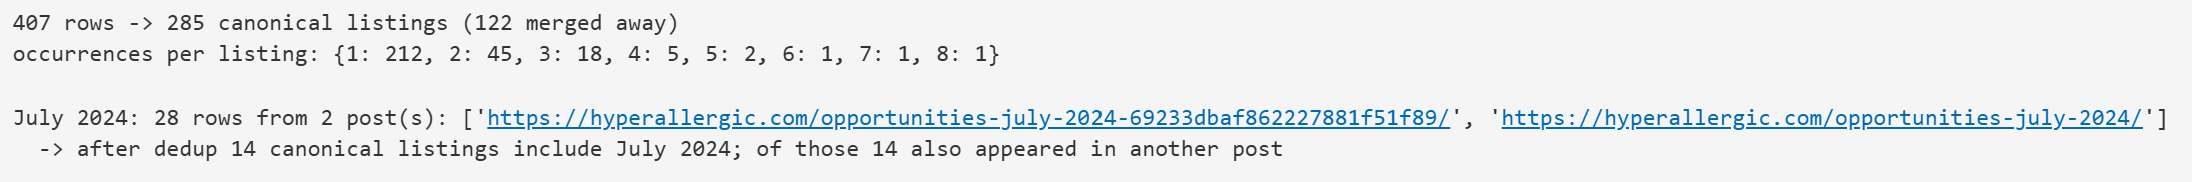

---
**Revised rules (after the spot check in the cells below).** The rules above are the first version. The spot check showed they wrongly merge different programs of one organizer, so the code now uses:

Titles look like `Organizer – Program` (e.g. `Vermont Studio Center – 2025 Residency`). The first version of this step compared whole titles with `token_set_ratio`, and the spot check showed two problems: the shared organizer name inflated every score, and a short title scored 100 against any longer title that contained its words (so `Hodder Fellowships` and `Princeton Arts Fellowships`, or `Grant for Sculpture` and `Grant for Writing on Sculpture`, got merged). So now:

1. Each title is split at the first dash into **organizer** and **program**, and **years are removed** (`2025`, `2026–27`), so the same program in different cycles still matches.
2. Programs are compared with `token_sort_ratio`, which sorts the words and compares the whole string, so it punishes a missing or extra word instead of ignoring it.

Two rows are the same opportunity when
- **Rule 1:** they share the same organizer link **and** their programs are similar (`>= 80`), **or**
- **Rule 2:** they have the same organizer (`token_set_ratio >= 90` on the organizer part, which tolerates `(LMCC)` or a leading `The`) **and** very similar programs (`>= 90`), **or**
- **Rule 3:** the full year-stripped titles are almost identical (`>= 95`), which covers titles with no dash.


Rows are still joined into clusters with union-find, and the canonical record is still the most recent post.

In [85]:
from rapidfuzz import process, fuzz

# newest post first, so the first row of each cluster is the canonical one.
# (Sorted BEFORE scoring so the score matrices below line up with the rows of L.)
L = L.sort_values(["published_at", "scraped_at"], ascending=False).reset_index(drop=True)

_DASH = re.compile(r"\s[\u2013\u2014-]\s")                 # "Organizer - Program"
_YEAR = re.compile(r"\b(?:19|20)\d{2}(?:\s*[\u2013\u2014/-]\s*(?:19|20)?\d{2})?\b")   # 2025, 2026-27, 2025/2026

def split_title(title):
    """Return (organizer, program) from "Organizer - Program": lower-cased, years and punctuation removed."""
    t = _YEAR.sub(" ", (title or "").lower())
    parts = _DASH.split(t, maxsplit=1)
    org, prog = (parts[0], parts[1]) if len(parts) == 2 else ("", parts[0])
    def tidy(s):
        s = re.sub(r"^the\s+", "", s.strip())              # leading "The"
        return re.sub(r"\s+", " ", re.sub(r"[^\w\s]", " ", s)).strip()
    return tidy(org), tidy(prog)

parts = [split_title(t) for t in L["title"]]
org = [o for o, _ in parts]
prog = [pr for _, pr in parts]
full = [f"{o} {pr}".strip() for o, pr in parts]

prog_score = process.cdist(prog, prog, scorer=fuzz.token_sort_ratio, workers=-1)
org_score = process.cdist(org, org, scorer=fuzz.token_set_ratio, workers=-1)
full_score = process.cdist(full, full, scorer=fuzz.token_sort_ratio, workers=-1)

keys = L["key"].to_numpy(dtype=object)
same_link = (keys[:, None] == keys[None, :]) & (keys[:, None] != "")
has_org = np.array([bool(o) for o in org])
same_org = (org_score >= 90) & has_org[:, None] & has_org[None, :]

rule1 = same_link & (prog_score >= 80)
rule2 = same_org & (prog_score >= 90)
rule3 = full_score >= 95
dup = rule1 | rule2 | rule3
np.fill_diagonal(dup, False)

parent = list(range(len(L)))                           # union-find
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
for i, j in zip(*np.where(np.triu(dup))):
    parent[find(i)] = find(j)
L["cluster"] = [find(i) for i in range(len(L))]

agg = L.groupby("cluster", sort=False).agg(
    months=("month", lambda s: sorted(set(s.dropna()))),
    source_urls=("source_url", lambda s: sorted(set(s))),
    member_titles=("title", lambda s: list(dict.fromkeys(s.dropna()))),
    all_deadlines=("deadline_iso", lambda s: sorted(set(s.dropna()))),
    n_occurrences=("title", "size"),
).reset_index()
canon = L.drop_duplicates("cluster", keep="first").merge(agg, on="cluster")

canon["listing_id"] = ["L" + hashlib.sha1(f"{k}|{t}".encode()).hexdigest()[:10] for k, t in zip(canon["key"], canon["title"])]
assert canon["listing_id"].is_unique

print(f"{len(L)} rows -> {len(canon)} canonical listings ({len(L) - len(canon)} merged away)")
print("occurrences per listing:", canon["n_occurrences"].value_counts().sort_index().to_dict())

# the July 2024 double: two posts for the same month
jul = L[L["month"] == "2024-07"]
print("\nJuly 2024:", len(jul), "rows from", jul["source_url"].nunique(), "post(s):", sorted(jul["source_url"].unique()))
jul_canon = canon[canon["months"].map(lambda m: "2024-07" in m)]
print("  -> after dedup", len(jul_canon), "canonical listings include July 2024;",
      "of those", int((jul_canon["n_occurrences"] > 1).sum()), "also appeared in another post")

drops["duplicate listings merged"] = (len(L) - len(canon), "same opportunity repeated across months or posts (incl. the July 2024 double); canonical = newest")

407 rows -> 299 canonical listings (108 merged away)
occurrences per listing: {1: 227, 2: 50, 3: 13, 4: 5, 5: 3, 6: 1}

July 2024: 28 rows from 2 post(s): ['https://hyperallergic.com/opportunities-july-2024-69233dbaf862227881f51f89/', 'https://hyperallergic.com/opportunities-july-2024/']
  -> after dedup 14 canonical listings include July 2024; of those 14 also appeared in another post


### Spot check: are any merges wrong?

`token_set_ratio` gives 100 when one title's words are all contained in the other's (e.g. `Artist Residency` vs `Wave Hill Artist Residency`). So a short generic title can be merged into an unrelated longer one. Rule 2 (titles alone, `>= 92`) has no link evidence to back it up, so it is the riskiest. This cell lists, for review by eye:

1. **Rule-2-only merges**: pairs merged by title alone (not the same link).
2. **Subset merges**: pairs where one title's words are fully inside the other's, which is where `token_set_ratio` over-scores.
3. **Weak chains**: clusters whose *least* similar pair scores low, meaning A~B and B~C pulled A and C together without A and C looking alike.

If real false merges show up, we'll tighten the rule in C4.

In [86]:
# Reuse the score matrices from C4 (they are in the same row order as L)
cl = L["cluster"].to_numpy()
ii, jj = np.where(np.triu(cl[:, None] == cl[None, :], k=1))
pairs = pd.DataFrame({
    "score": prog_score[ii, jj], "same_link": same_link[ii, jj],
    "rule1": rule1[ii, jj], "rule2": rule2[ii, jj], "rule3": rule3[ii, jj],
    "title_a": L["title"].to_numpy()[ii], "title_b": L["title"].to_numpy()[jj], "cluster": cl[ii],
})
pairs["direct"] = pairs[["rule1", "rule2", "rule3"]].any(axis=1)
pairs["title_only"] = ~pairs["rule1"] & (pairs["rule2"] | pairs["rule3"])
pd.set_option("display.max_colwidth", 80, "display.width", 250, "display.max_columns", None)
show = ["score", "title_a", "title_b"]

print("pairs inside clusters:", len(pairs), "| rule 1 (same link):", int(pairs["rule1"].sum()),
      "| title only:", int(pairs["title_only"].sum()), "| only chained:", int((~pairs["direct"]).sum()))

print("\n1) Title-only merges, excluding exact title repeats:")
t_only = pairs[pairs["title_only"] & (pairs["title_a"].str.lower() != pairs["title_b"].str.lower())]
print(len(t_only), "pairs")
print(t_only.sort_values("score")[show].head(30).to_string())

print("\n2) Weak chains (in the same cluster only through a third row):")
chained = pairs[~pairs["direct"]]
print(len(chained), "pairs chained only")
print(chained.sort_values("score")[show].head(15).to_string())

print("\n3) Pairs whose program parts differ a lot (score < 60):")
diff = pairs[pairs["score"] < 60]
print(len(diff), "pairs in", diff["cluster"].nunique(), "clusters")
print(diff.sort_values("score")[show].head(15).to_string())

# the cases the first version got wrong
for b in ["Hodder Fellowships", "Grant for Writing on Sculpture", "Haystack at 75", "Core & Steepletop"]:
    hit = L[L["title"].str.contains(b, regex=False)]
    print(f"\n'{b}': {len(hit)} row(s), cluster sizes", [int((cl == c).sum()) for c in hit["cluster"].unique()])

pairs inside clusters: 164 | rule 1 (same link): 114 | title only: 48 | only chained: 2

1) Title-only merges, excluding exact title repeats:
32 pairs
          score                                                                                                        title_a                                                                                      title_b
32    44.444443                    2027 Erie Canal Artists in Residence — Erie Canal Museum & New York State Canal Corporation  Erie Canal Museum & New York State Canal Corporation – 2026 Erie Canal Artists in Residence
33    44.444443                    2027 Erie Canal Artists in Residence — Erie Canal Museum & New York State Canal Corporation  Erie Canal Museum & New York State Canal Corporation – 2025 Erie Canal Artists in Residence
20    58.064518                                                                        Foundwork – 2026 Foundwork Artist Prize                                                      2026 Foun



Previous version (based on 2 rules):

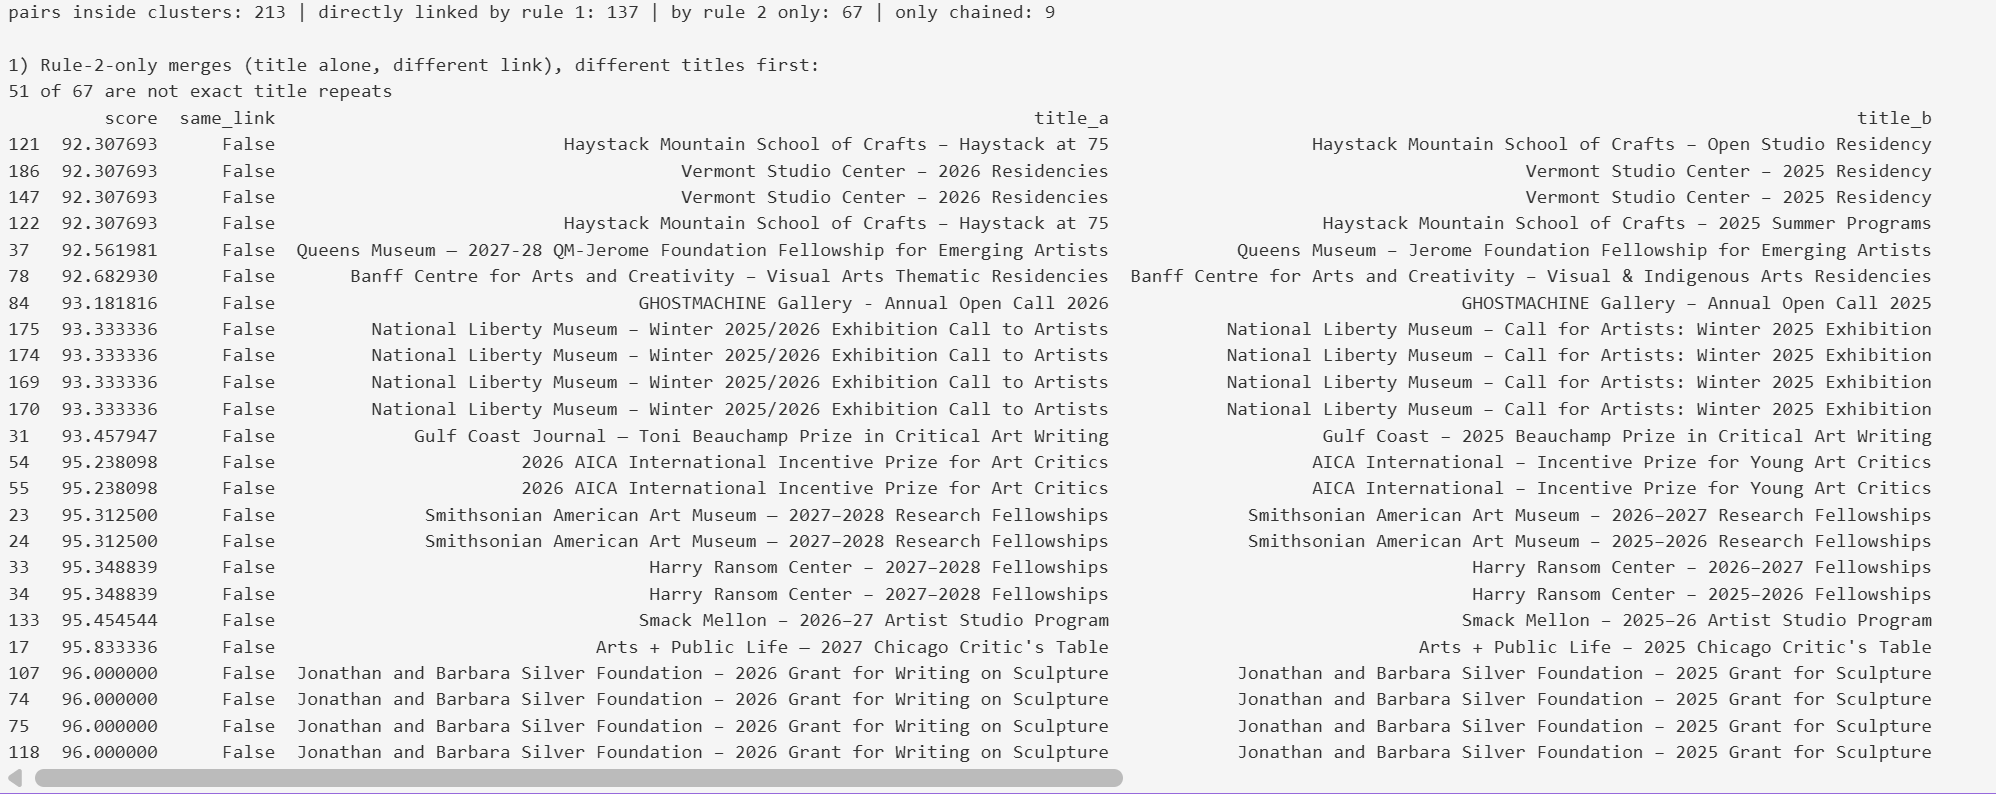
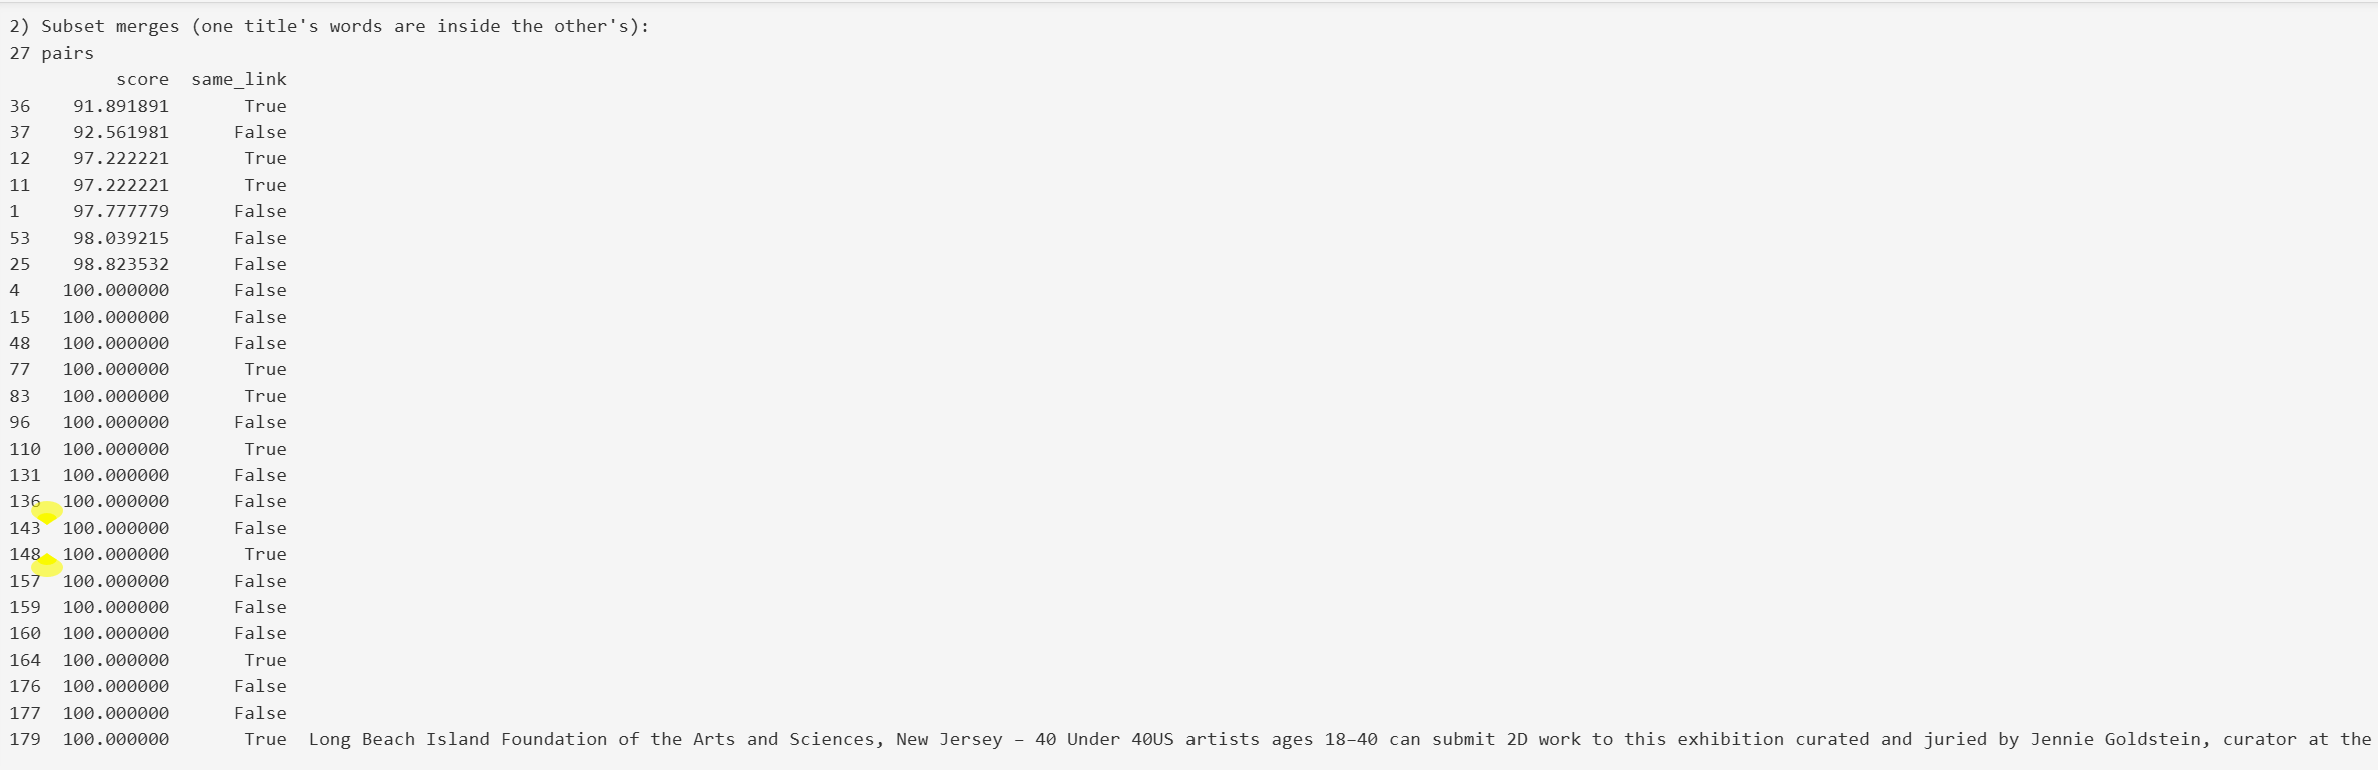
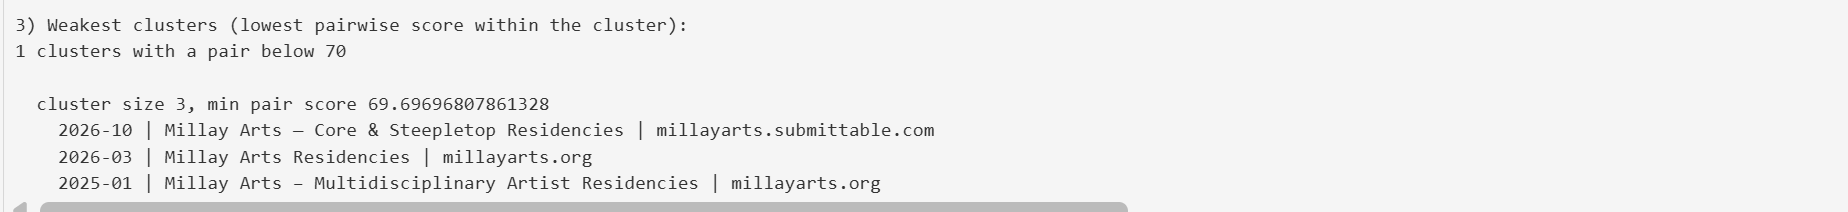

Most of what rule 2 merges (67) are fine. These are the same program in a different year, which is the intended behavior:

Vermont Studio Center 2025 vs 2026
Smithsonian 2025–26 vs 2026–27
Harry Ransom Center fellowships across years
Smack Mellon 2025–26 vs 2026–27

**Likely wrong merges**
- Silver Foundation: 2026 Grant for Writing on Sculpture was merged with 2025 Grant for Sculpture, which look like two different grants. This merge happened 5 times.
- Lewis Center: Hodder Fellowships and Princeton Arts Fellowships are different fellowships. They scored 100.
- Haystack: Haystack at 75, Open Studio Residency and 2025 Summer Programs are different programs. They scored 92.
- Banff: Visual Arts Thematic Residencies and Visual & Indigenous Arts Residencies are probably separate programs.
- Millay Arts: Core & Steepletop Residencies was chained to the generic Millay Arts Residencies. That cluster has the lowest pairwise score, 69.7.

**Why it happens.** Titles look like Organizer – Program. The long organizer name is identical in both titles, so it makes the score high even when the program names differ. A short program name that is a subset of a longer one scores 100.

It looks like we need to make some changes to avoid certain fixes:
 Split each title at the dash and compare only the program part, and require the same organizer name for a rule-2 merge. Year numbers would be stripped before comparing, so different cycles of one program still merge. That would keep the Smithsonian and Vermont merges and split Hodder/Princeton, Silver Foundation and Haystack.



Also, there are 9 weak chains - these 9 pairs matched neither rule and are in the cluster only because of the chain. The Millay Arts cluster shows it, with three rows:

A:	Millay Arts – Core & Steepletop Residencies, Domain:	millayarts.submittable.com <br>
B:	Millay Arts Residencies, Domain:	millayarts.org <br>
C:	Millay Arts – Multidisciplinary Artist Residencies, Domain:	millayarts.org <br>

- B and C share a link and their titles are similar enough, so rule 1 joins them. <br>
- A and B score 100 as a subset, so rule 2 joins them. <br>
- A and C score only about 70, so neither rule matches them. They are in the same cluster only through B.

Chaining is what makes the shared generic title Millay Arts Residencies pull in two different programs. This is the risk of the approach: one loose link can merge groups that don't belong together. The check's third part flags these clusters by looking for a low minimum pair score.

---------------------------------------------------------------

**Result after the fix:** The two notes above describe the first version of the rules. With the revised rules the spot check cell above re-runs on the new clusters:

- Canonical listings went from 285 to **299** (108 merged away instead of 122), so the 14 extra listings are programs that were wrongly merged before.
- Silver Foundation `Grant for Writing on Sculpture` (2026) and `Grant for Sculpture` (2025) are now separate. Hodder and Princeton Arts Fellowships, Haystack's three programs, and Millay's three programs are all separate too.
- Same program in different years still merges (Vermont, Smithsonian, Harry Ransom, Smack Mellon, Ucross).
- Weak chains dropped from 9 pairs to 2 (the AICA Incentive Prize, whose title was reworded: `Art Critics` vs `Young Art Critics`).
- Titles written in reverse order (`2026 Foundwork Artist Prize – Foundwork`) are still caught, by rule 3 on the full title.

#### Review list: merges that differ by a word

The spot check above catches merges that look very different. One case it cannot decide by itself is a pair that is *almost* the same, for example Banff's `Visual Arts Residencies` and `Visual Arts Thematic Residencies`. Whether these are one program or two is a fact about the real world, so code cannot settle it. What code can do is **make a short list for a human to check**.

For every pair of rows that ended up in the same cluster, this cell looks at three signals:

1. **Differing words.** The words that appear in one program title but not the other (years are already removed). If nothing differs, the pair is an exact repeat or a year change, which is safe and is skipped.
2. **Description similarity** (`desc_sim`, 0-100). Two listings for the same call usually have similar blurbs. A low score next to differing words suggests two different programs.
3. **Deadline and month.** Two rows from the **same post month** with **different deadlines** are two separate calls announced together, so they should not be one listing. (Rows from different months or years are expected to have different deadlines, so that case is not flagged.)

A pair is marked `suspicious` if its descriptions are dissimilar (`desc_sim < 60`) or if it has the same month with different deadlines. How to read the table:

| Pattern | Likely meaning |
|---|---|
| differing words and low `desc_sim` | two different programs: should be split |
| one differing word and high `desc_sim` | the same call, reworded: a correct merge |
| same month, different deadline | two calls in one post: should be split |

We didn't change anything here. It is only a list to check by hand. If a merge turns out to be wrong, the fix is a small override set (`NEVER_MERGE`) applied to the match matrix `dup` in step 4 before the clusters are built.

In [87]:
# For every pair inside a cluster, list the program words that differ and compare descriptions / deadlines.
# Reuses ii, jj (index pairs inside the same cluster), L and split_title from the cells above.
def program_words(title):
    return set(split_title(title)[1].split())          # program part of the title, years already removed

rows = []
for a, b in zip(ii, jj):
    diff = program_words(L.at[a, "title"]) ^ program_words(L.at[b, "title"])   # in one title but not the other
    if not diff:
        continue                                        # same words: exact repeat or year change only, safe
    desc_a, desc_b = L.at[a, "description"] or "", L.at[b, "description"] or ""
    rows.append({
        "differing_words": sorted(diff),
        "desc_sim": round(fuzz.token_set_ratio(desc_a, desc_b)),
        "same_month": L.at[a, "month"] == L.at[b, "month"],
        "same_deadline": L.at[a, "deadline_iso"] == L.at[b, "deadline_iso"],
        "title_a": L.at[a, "title"], "title_b": L.at[b, "title"],
    })

review = pd.DataFrame(rows)
review["suspicious"] = (review["desc_sim"] < 60) | (review["same_month"] & ~review["same_deadline"])
# one row per distinct pair of titles (the same pair repeats when a listing appeared in several months)
review = review.drop_duplicates(["title_a", "title_b"]).sort_values(["suspicious", "desc_sim"], ascending=[False, True])

print(len(review), "distinct merged title pairs differ by at least one program word;",
      int(review["suspicious"].sum()), "look suspicious")
print(review.to_string(index=False))

16 distinct merged title pairs differ by at least one program word; 6 look suspicious
                                                differing_words  desc_sim  same_month  same_deadline                                                                                                       title_a                                                                                     title_b  suspicious
                                   [aica, international, young]        50       False          False                                                       2026 AICA International Incentive Prize for Art Critics                                  AICA International – Incentive Prize for Young Art Critics        True
                                          [aica, international]        51       False          False                                                       2026 AICA International Incentive Prize for Art Critics                                        AICA International – Incentive Pri

**What the review list shows**

- 16 distinct merged title pairs differ by at least one program word, and 6 are marked `suspicious`. None of the 16 is a same-month pair with different deadlines, so there is no sign of two calls from one post being merged.
- **All 6 flagged pairs look like false alarms**, caused by how the titles are written rather than by different programs:
  - AICA `2026 AICA International Incentive Prize...` vs `AICA International - Incentive Prize...` (the organizer name is written differently or sits in front of the year)
  - Paul & Daisy Soros (a leading `The`)
  - Foundwork and Erie Canal (some titles are `Program - Organizer` instead of `Organizer - Program`, so organizer words land in the "program" part and count as differing words)
  - National Liberty Museum (`Call to Artists` vs `Call for Artists`, different wording of one call)
- The rest are small wording changes of one program: `Yaddo Artist Residency` vs `Residencies`, the Queens Museum `QM-` prefix, the A.I.R. Fellowship `Program`, AICA `Young`.
- **Textile Arts Center `Cycle 17` vs `Cycle 18`**: the same program with a cycle number instead of a year, so the year-stripping does not remove it. The descriptions are 92% similar and it is the same kind of merge as `2025` vs `2026`, so it is kept as one listing.
- **Banff `Visual Arts Residencies` vs `Visual Arts Thematic Residencies` stays unresolved.** The description similarity is 71, which is neither clearly the same call nor clearly different, and it is not flagged. It needs a person to compare the two descriptions and the organizer page. It is one pair, so it can stay merged for now.

**Conclusion:** the rules from step 4 hold up. No merge on this list clearly needs to be split. Two limits to remember: titles written program-first make the differing-word list noisy, and a person still has to decide the Banff case. If a bad merge does turn up later, add it to a `NEVER_MERGE` set applied to `dup` in step 4.

In [88]:
# Manual check: open the links of every row in the cluster(s) whose title matches `needle`.
# Use it for any merge you want to verify by eye (the Banff pair is the first one).
from IPython.display import HTML, display

def inspect_merge(needle, rows=L):
    """Show, for each cluster with a title containing `needle`, every row that was merged into it:
    the title, post month, deadline, the organizer link, the Hyperallergic post, and the blurb."""
    hits = rows[rows["title"].str.contains(needle, case=False, regex=False)]
    for c in hits["cluster"].unique():
        members = rows[rows["cluster"] == c].sort_values("published_at")
        print(f"cluster {c}: {len(members)} row(s), {members['title'].nunique()} distinct title(s)")
        html = ["<table style='text-align:left'><tr><th>month</th><th>title</th><th>deadline</th><th>organizer page</th><th>Hyperallergic post</th></tr>"]
        for _, r in members.iterrows():
            html.append(
                f"<tr><td>{r['month']}</td><td>{r['title']}</td><td>{r['deadline'] or ''}</td>"
                f"<td><a href='{r['website']}' target='_blank'>{r['website']}</a></td>"
                f"<td><a href='{r['source_url']}' target='_blank'>post</a></td></tr>")
        display(HTML("".join(html) + "</table>"))
        # the blurbs, one per distinct title, so they can be compared line by line
        for _, r in members.drop_duplicates("title").iterrows():
            print(f"\n[{r['month']}] {r['title']}\n  {r['description']}")
        # plain-text links too, in case the notebook viewer does not render HTML
        print("\nLinks:")
        for url in dict.fromkeys(list(members["website"]) + list(members["source_url"])):
            print(" ", url)

inspect_merge("Banff Centre for Arts and Creativity")   # shows the Banff cluster(s); the third Banff row is a different cluster

cluster 144: 2 row(s), 2 distinct title(s)


month,title,deadline,organizer page,Hyperallergic post
2025-10,Banff Centre for Arts and Creativity – Visual Arts Residencies,"November 19, 2025 (Visual Arts – Nomadisms), January 21, 2026 (Banff Artist in Residence Summer 2026)",https://www.banffcentre.ca/visual-arts,post
2026-04,Banff Centre for Arts and Creativity – Visual Arts Thematic Residencies,"May 6, 2026 (Visual Arts Thematic – On Other Archives), June 3, 2026 (Visual Arts Thematic – Future Figurations)",https://www.banffcentre.ca/visual-arts,post



[2025-10] Banff Centre for Arts and Creativity – Visual Arts Residencies
  Explore new directions in your work and benefit from time, studio space, facilities, feedback, and engagement with peers and faculty in an unrivaled natural environment in the Canadian Rocky Mountains. The application fee is $65 ($35 for applicants who identify as Indigenous). Read more on Hyperallergic.

[2026-04] Banff Centre for Arts and Creativity – Visual Arts Thematic Residencies
  Develop your work in a Visual Arts residency at Banff Centre. Access exceptional studios, mentorship from leading faculty, and a vibrant artistic community in the Canadian Rockies. The application fee is $65 ($35 for applicants who identify as Indigenous). Read more on Hyperallergic.

Links:
  https://www.banffcentre.ca/visual-arts
  https://hyperallergic.com/opportunities-october-2025/
  https://hyperallergic.com/opportunities-april-2026/
cluster 300: 1 row(s), 1 distinct title(s)


month,title,deadline,organizer page,Hyperallergic post
2024-12,Banff Centre for Arts and Creativity – Visual & Indigenous Arts Residencies,"January 29, 2025 (Visual Arts – Kapishkum), February 26, 2025 (Early Career BAiR Summer 2025), May 7, 2025 (Indigenous Arts – Aknumustiǂis)",https://www.banffcentre.ca/programs,post



[2024-12] Banff Centre for Arts and Creativity – Visual & Indigenous Arts Residencies
  Explore new directions in your work and benefit from time, studio space, facilities, feedback, and engagement with peers and faculty in an unrivaled natural environment in the Canadian Rocky Mountains. The application fee is $65 ($35 for applicants who identify as Indigenous). Read more on Hyperallergic.

Links:
  https://www.banffcentre.ca/programs
  https://hyperallergic.com/opportunities-december-2024/


Checked these listings manually - Both listings point to the same organizer page and have the same application fee ($65, or $35 for Indigenous applicants). The blurbs differ only in wording, so this points to the same program, hence keeping them merged. 

The third Banff row, Visual & Indigenous Arts Residencies, is a separate cluster (300). Its organizer page is https://www.banffcentre.ca/programs, and its blurb is nearly the same as the first listing's. 

To check a different merge, call inspect_merge("some title text").

**Next steps:**

Depending on what we decide from the inspection, we will do the following:

`If they are one program:` we do nothing. They are already merged, so the data is correct. 

`If they are different programs:` the merge has to be undone in the code. Editing data/clean/ by hand won't work, because the next run would rebuild the files with the same merge. There is no override mechanism in step 4 yet. These are the steps:

Add an override in step 4. Add a NEVER_MERGE set of title pairs, for example ("Banff ... Visual Arts Residencies", "Banff ... Visual Arts Thematic Residencies"). Before the clusters are built, set dup to False for those pairs. If the two rows are also joined through a third row, which is the chaining problem, that pair needs a check too.<br>

Re-run from step 4 to the end. The canonical listing count goes from 299 to 300. Listing IDs, page merge, chunks and splits are all rebuilt, and data/clean/ and data_report.md are rewritten. The splits shift slightly, which is why this should happen before any labeling.<br>

Then check the result. Run inspect_merge("Banff") again and confirm the two listings are now separate clusters.

In [89]:
# ---------------------------------------------------------------------------------------------
# NEXT STEP AFTER THE MANUAL CHECK (everything below is commented out on purpose)
#
# If you decide the two Banff listings are DIFFERENT programs, they must be kept apart in step 4.
# If you decide they are the same program, do nothing: they are already merged.
#
# WHERE TO ADD IT: in the step 4 code cell ("from rapidfuzz import process, fuzz ..."), directly
# AFTER this line:
#       dup = rule1 | rule2 | rule3
# and BEFORE this line:
#       np.fill_diagonal(dup, False)
# Paste the whole block below there (uncommented), then re-run the notebook from step 4 down to the end,
# so listing ids, the page merge, chunks, splits and data/clean/ are rebuilt.
#
# --- block to paste ---------------------------------------------------------------------------
# # Pairs a human checked and decided are different programs. Each entry is
# # (organizer text, ending of title A, ending of title B); a title matches if it contains the
# # organizer text and ends with the given words, so the dash character in the title does not matter.
# NEVER_MERGE = [
#     ("Banff Centre", "Visual Arts Residencies", "Visual Arts Thematic Residencies"),
# ]
#
# def rows_matching(organizer, ending):
#     m = L["title"].str.contains(organizer, regex=False) & L["title"].str.endswith(ending)
#     return np.where(m)[0]                          # positions in L (same order as the dup matrix)
#
# for organizer, ending_a, ending_b in NEVER_MERGE:
#     for a in rows_matching(organizer, ending_a):
#         for b in rows_matching(organizer, ending_b):
#             dup[a, b] = dup[b, a] = False          # these two rows can no longer be linked directly
# --- end of block -----------------------------------------------------------------------------
#
# AFTER RE-RUNNING, CHECK:
#   1. inspect_merge("Banff Centre")  -> the two listings should now be in different clusters.
#      If they are STILL in one cluster, a third row links them (the chaining problem); add that
#      pair to NEVER_MERGE as well.
#   2. The printed count in step 4 should go from 299 to 300 canonical listings.
#   3. Anything that was written to data/clean/ earlier is replaced by the re-run, so do this before
#      any labeling starts (listing ids and splits can change).

### 5. Merge page text onto the listings

Each canonical listing is joined to its organizer page by `key` (the cleaned link). Two columns answer different questions, so they are kept apart:

- `page_fetched`: a page row exists for this link at all.
- `has_page`: the page survived cleaning, so `page_text` is **usable text**. (This is the stricter meaning, the old EDA `page_usable`.) `page_problem` says why a fetched page was rejected.

Listings without usable text are **kept** (their blurb and fields are still useful), they just have `has_page = False` and contribute no chunks.

In [90]:
canon = canon.merge(pg, on="key", how="left")
canon["page_fetched"] = canon["page_problem"].notna() | canon["page_text"].notna()
canon["has_page"] = canon["page_text"].notna()

print("canonical listings:", len(canon))
print("organizer page fetched :", int(canon["page_fetched"].sum()))
print("usable page (has_page) :", int(canon["has_page"].sum()))
print("no usable page         :", int((~canon["has_page"]).sum()))
drops["listings without usable page text"] = (int((~canon["has_page"]).sum()), "kept, but has_page=False and no chunks")

canonical listings: 299
organizer page fetched : 236
usable page (has_page) : 215
no usable page         : 84


#### Why do some listings have no usable page text?

The numbers above show that a share of the canonical listings has no usable organizer page. Before deciding what to do about it (fetch more, ask for permission, or accept the loss), we need to know **why** each one is missing, because the causes have different fixes. This cell gives every listing without a usable page exactly one reason:

| Reason | Meaning | Possible fix |
|---|---|---|
| `no link` | the listing has no organizer link, or it is not an http link | none, the blurb is all we have |
| `skipped: <domain>` | the fetch script never fetches this site (social media, short links, application forms, aggregators, and sites whose terms forbid automated access; the list is `SKIP_DOMAINS` in `fetch_opportunity_page.py`) | none without permission, or a different source |
| `rejected: <problem>` | a page was fetched but cleaning rejected it (`not_found`, `no_signal`, or `empty`) | check by hand, the link may have moved |
| `not fetched` | the link is allowed but no page was saved: blocked by `robots.txt`, a failed fetch, or the fetch has not been run | re-run the fetch script, or check robots.txt |

The cell also shows how the missing pages are spread over the three types and over organizers. That matters because **missing pages that are not random bias the training text**: if one type loses far more pages than the others, the model sees less of that type.

In [ ]:
# Give every listing without usable page text one reason. Uses the same skip list as the fetch script.
sys.path.insert(0, str(ROOT / "scrapers" / "hyperallergic"))
from fetch_opportunity_page import SKIP_DOMAINS, is_skipped
from common import clean_url

def missing_reason(row):
    if row["has_page"]:
        return None
    url = clean_url(row["website"] or "")
    if not url.startswith("http"):
        return "no link"
    if is_skipped(url):
        host = urlparse(url).netloc.lower()
        matched = next((d for d in SKIP_DOMAINS if host == d or host.endswith("." + d)), host)
        return f"skipped: {matched}"
    if row["page_fetched"]:
        return f"rejected: {row['page_problem']}"
    return "not fetched"

canon["missing_reason"] = canon.apply(missing_reason, axis=1)
missing = canon[~canon["has_page"]]
print(f"{len(missing)} of {len(canon)} listings have no usable page text ({len(missing) / len(canon):.0%})\n")

print("By reason:")
print(missing["missing_reason"].value_counts().to_string())

# is the loss the same for every type? (a type that loses far more pages is under-represented in the text)
by_type = canon.groupby("type").agg(listings=("listing_id", "size"), no_page=("has_page", lambda s: int((~s).sum())))
by_type["no_page_%"] = (by_type["no_page"] / by_type["listings"] * 100).round(0)
print("\nBy type:")
print(by_type.to_string())

# which organizers lose the most listings?
print("\nOrganizers with the most listings missing a page:")
print(missing["domain"].replace("", "(no domain)").value_counts().head(10).to_string())

# links that should have been fetched but were not: worth opening by hand
nf = missing[missing["missing_reason"] == "not fetched"]
print(f"\nAllowed links with no saved page ({len(nf)}):")
for _, r in nf.head(25).iterrows():
    print(" ", r["website"])

**What the breakdown shows** (84 of 299 listings, 28%, have no usable page text)

| Reason | Listings | Share of the 84 |
|---|---|---|
| not fetched (link allowed, no saved page) | 53 | 63% |
| rejected after fetching (10 not found, 7 no signal, 4 empty) | 21 | 25% |
| skipped domain (6 submittable.com, jotform, Google Docs, Creative Capital) | 9 | 11% |
| no link | 1 | 1% |

- **The biggest cause is fetching, not cleaning or the skip list.** The fetch script finds 305 unique links it is allowed to fetch, but the pages file has 251 pages, so 54 allowed links have no page. None of the 53 matching listings has a cache file, so they were not fetched and then lost. Either the fetch run stopped early, or `robots.txt` blocked them (a blocked page is not cached or saved, so the two cannot be told apart from the data). Re-running the fetch script, which skips pages already saved, would show which. It costs about one Firecrawl credit per page, so the 54 would cost about 54 credits.
- **Cleaning rejected only 21.** Most are error pages (10 not found), so these links may have moved and are worth opening by hand.
- **The skip list costs 9 listings.** Application platforms such as Submittable hold little text anyway.
- **Open Calls lose the most:** 41% have no page, against 23% for Grant/Fellowship and 25% for Residency. So the text we can label is skewed toward grants and residencies, and Open Calls are under-represented. This matters for the type balance of the training chunks and should be mentioned when reporting results by type.
- **Only 1 of the 53 could be recovered without fetching.** For that listing, another row merged into the same cluster has a usable page. A fallback of "use the page of any member of the cluster when the canonical row has none" would recover it. It is small, so it is not applied now.
- **Organizers are spread out.** No organizer loses more than 2 listings, so there is no single site to fix.

**Next step:** re-run the fetch script (dry run first) for the 54 missing allowed links, then re-run the notebook from step 2. If many are blocked by `robots.txt`, accept the loss and report the Open Call gap.

- So about 28% of the 299 (84/299) listings have no usable organizer page text. For those listings we only have the Hyperallergic blurb.
- 84 without usable text come from two different causes:
    - 63 listings never had a page fetched (299 minus 236). The listing either has no link or its link was never fetched.
    - 21 had a page fetched but rejected it (236 minus 215). These are the error pages, login walls and near-empty pages from step 2. That is about 9% of fetched pages, which fits the EDA's 25 bad pages out of 251.

- The bigger loss is pages we never got, not pages we rejected. Cleaning only cost us 21 listings. Fetching cost us 63. If we want more text, the lever is fetching, not loosening the cleaning rules.
- Usable data is smaller than it looks. There are 299 unique listings, but only 215 can give chunk-level text for labeling. 
    - The original target was 400 unique cleaned listings, so we are about 100 short on listings and 185 short on listings with text. 
    - The 215 will also be split three ways, giving about 150 for training. This is enough for a 30 to 40 listing gold set but thin for fine-tuning.
- Deduplication did not change the rate. Before the title fix, 202 of 285 (71%) were usable; now it is 215 of 299 (72%). So the 14 extra listings from the fix brought their share of pages with them.
- The missing pages may not be random. The fetch script skipped social media, forms, and sites whose terms forbid scraping. If those are mostly one type, for example Open Calls on Instagram or forms, then the text we train on is biased toward organizers with simple websites. 
- But we are not sure yet: why the 63 pages were never fetched. It could be a skipped domain, a missing link, a link that changed after cleaning, or just not run yet. All these have different fixes, such as asking permission, fetching more, or accepting the loss.

A good next check is a breakdown of the 84 by reason (no link, skipped domain, not yet fetched, rejected), by type, and by domain. 

### 6. Chunking

A DeBERTa model reads at most 512 tokens, and 78% of usable pages are longer. So each page is cut into **overlapping windows**.

- **Size:** the real DeBERTa tokenizer is not installed locally (it runs in Colab), so we use the EDA's rule of thumb, tokens ≈ words × 1.3. A window of **300 words ≈ 400 tokens**.
- **Overlap:** the window advances by 240 words, so neighbouring chunks share 60 words (about 20%). A deadline sentence cut in half by one window is whole in the next.
- **Tail:** a leftover shorter than 40 words is absorbed into the last window instead of becoming a tiny chunk (the longest window is therefore 340 words ≈ 440 tokens, still under 512).
- **Offsets:** each chunk records `char_start/char_end` on the cleaned page text and `raw_start/raw_end` on the original text, so a label made on a chunk can be placed on the whole page and the source.
- **IDs:** chunks are made once per *page* (not per listing), because several listings can share a page (e.g. apexart). Each chunk lists `listing_ids` for every listing it belongs to, which is what a grouped split needs.

In [ ]:
WINDOW, STRIDE, MIN_TAIL = 300, 240, 40               # in words; ~400 tokens, 20% overlap

def chunk_page(text):
    """Yield (char_start, char_end) windows over `text`, cut on word boundaries."""
    words = [(m.start(), m.end()) for m in re.finditer(r"\S+", text)]
    n, i = len(words), 0
    while True:
        j = min(i + WINDOW, n)
        if n - j < MIN_TAIL:                           # absorb a short tail into this last window
            j = n
        yield words[i][0], words[j - 1][1]
        if j == n:
            break
        i += STRIDE

# which listings use each page
page_listings = canon[canon["has_page"]].groupby("key")["listing_id"].apply(list).to_dict()

chunk_rows = []
for _, r in pg[pg["page_text"].notna()].iterrows():
    if r["key"] not in page_listings:                  # page exists but no canonical listing points at it
        continue
    spans = list(chunk_page(r["page_text"]))
    pid = hashlib.sha1(r["key"].encode()).hexdigest()[:8]
    for k, (a, b) in enumerate(spans):
        ra, rb = clean_to_raw_span(r["page_offsets"], a, b, len(r["page_text_raw"]))
        txt = r["page_text"][a:b]
        chunk_rows.append({
            "chunk_id": f"{pid}-{k:03d}", "page_key": r["key"], "listing_ids": page_listings[r["key"]],
            "chunk_index": k, "n_chunks": len(spans),
            "char_start": a, "char_end": b, "raw_start": ra, "raw_end": rb,
            "n_words": len(txt.split()), "est_tokens": round(len(txt.split()) * 1.3), "text": txt,
        })
chunks = pd.DataFrame(chunk_rows)

print("chunks:", len(chunks), "from", chunks["page_key"].nunique(), "pages")
print("chunks per page:", chunks.groupby("page_key").size().describe().round(1).to_dict())
print("est. tokens per chunk:", chunks["est_tokens"].describe().round(0).to_dict())
assert (chunks["est_tokens"] < 512).all()
# every chunk text must be exactly the slice of its page
check = pg.set_index("key")["page_text"]
assert all(check[c.page_key][c.char_start:c.char_end] == c.text for c in chunks.itertuples())

## C7. Train / validation / test split

**Rule: the unit of splitting is the organizer (`domain`), not the listing or the chunk.** This gives three guarantees at once:

1. No organizer appears in more than one split, so the test score measures how the model handles organizers it has never seen (the leakage issue from the EDA).
2. Duplicates were already collapsed in C4, so one opportunity is one listing and cannot straddle splits.
3. Every chunk inherits the split of its listing(s), so chunks of one page never get separated. (A page shared by several listings has one domain, so they all go to the same split. The code asserts this.)

Method: whole organizers are shuffled with a **fixed seed** (`SEED = 42`), then assigned largest-first to whichever split is furthest below its target share (70 / 15 / 15). Largest-first stops one big organizer from unbalancing a small split. A listing with no domain is its own group.

In [ ]:
RATIOS = {"train": 0.70, "val": 0.15, "test": 0.15}

canon["group"] = np.where(canon["domain"].fillna("") != "", canon["domain"], "no-domain:" + canon["listing_id"])
group_size = canon.groupby("group").size()

rng = random.Random(SEED)
order = list(group_size.index)
rng.shuffle(order)                                     # random tie-breaking...
order.sort(key=lambda g: -group_size[g])               # ...then biggest groups first (stable sort keeps the shuffle for ties)

target = {s: r * len(canon) for s, r in RATIOS.items()}
filled = {s: 0 for s in RATIOS}
group_split = {}
for g in order:
    s = max(RATIOS, key=lambda s: target[s] - filled[s])   # split with the largest remaining deficit
    group_split[g] = s
    filled[s] += group_size[g]
canon["split"] = canon["group"].map(group_split)

# ---- leakage checks ----
dom_splits = canon.groupby("group")["split"].nunique()
assert (dom_splits == 1).all(), "an organizer sits in two splits"
split_of = canon.set_index("listing_id")["split"]
chunks["split"] = chunks["listing_ids"].map(lambda ids: split_of[ids].unique().tolist())
assert chunks["split"].map(len).eq(1).all(), "a page is shared by listings in different splits"
chunks["split"] = chunks["split"].str[0]

print(pd.DataFrame({"listings": canon["split"].value_counts(), "organizers": canon.groupby("split")["group"].nunique(),
                    "chunks": chunks["split"].value_counts()}).reindex(list(RATIOS)).to_string())
print("\nlisting type mix per split (%):")
print(pd.crosstab(canon["split"], canon["type"], normalize="index").mul(100).round(1).to_string())

## C8. Outputs

Everything is written to `data/clean/`:

| File | Content |
|---|---|
| `listings.jsonl` | one row per canonical listing: normalized fields, `*_raw` originals, parsed deadline/fees/type, `months`, `page_text`, `page_text_raw`, `page_offsets`, `has_page` |
| `chunks.jsonl` | one row per chunk: text, clean and raw character offsets, `listing_ids` |
| `splits.json` | the seed, ratios and the listing / chunk / organizer IDs of each split |
| `data_report.md` | what was dropped or flagged, and why (generated from the `drops` log) |

`page_offsets` entries are `[clean_start, raw_start, length]`; use `clean_to_raw_span` (above) to convert a label span back to the raw page. Files are rewritten on every run and are deterministic given the seed.

In [ ]:
list_cols = ["listing_id", "split_group", "title", "title_raw", "description", "description_raw", "type", "type_raw",
             "deadline", "deadline_raw", "deadline_iso", "deadline_dates", "all_deadlines", "deadline_source",
             "is_rolling", "deadline_suspect", "fees", "fees_raw", "fee_mentioned", "fee_min", "fee_max", "fee_currency",
             "fee_is_application", "fee_free", "website", "key", "domain", "months", "n_occurrences", "source_urls",
             "member_titles", "published_at", "page_fetched", "has_page", "page_problem", "page_text", "page_text_raw",
             "page_offsets", "boilerplate_lines_removed"]
canon["split_group"] = canon["group"]
out_listings = canon[list_cols].copy()
out_listings["published_at"] = out_listings["published_at"].astype(str)
out_listings.to_json(CLEAN_DIR / "listings.jsonl", orient="records", lines=True, force_ascii=False)

chunks.drop(columns=["split"]).to_json(CLEAN_DIR / "chunks.jsonl", orient="records", lines=True, force_ascii=False)

splits = {
    "seed": SEED, "ratios": RATIOS, "unit": "organizer domain (listings with no domain are their own group)",
    "chunk_unit": "chunks inherit the split of their listing(s)",
    **{s: {"listing_ids": sorted(canon.loc[canon["split"] == s, "listing_id"]),
           "chunk_ids": sorted(chunks.loc[chunks["split"] == s, "chunk_id"]),
           "organizers": sorted(canon.loc[canon["split"] == s, "group"].unique())} for s in RATIOS},
}
(CLEAN_DIR / "splits.json").write_text(json.dumps(splits, indent=2, ensure_ascii=False), encoding="utf-8")

# ---------- data_report.md ----------
flags = {"possible non-U.S. (EDA keyword flag, not dropped)": int(df["flag_non_us"].sum()) if "flag_non_us" in df else "n/a",
         "possible odd type: workshop/festival/job (EDA keyword flag, not dropped)": int(df["flag_not_target_type"].sum()) if "flag_not_target_type" in df else "n/a"}
report = [
    "# Data report (Phase C preprocessing)", "",
    f"Generated by `notebooks/EDA+Preprocessing.ipynb`. Seed: {SEED}.", "",
    "## Funnel", "",
    f"- Raw listings: {len(listings)} from {listings['source_url'].nunique()} Hyperallergic posts",
    f"- Canonical listings after deduplication: {len(canon)}",
    f"- Canonical listings with usable page text: {int(canon['has_page'].sum())}",
    f"- Chunks: {len(chunks)} from {chunks['page_key'].nunique()} pages",
    f"- Split (listings): " + ", ".join(f"{s} {int((canon['split'] == s).sum())}" for s in RATIOS), "",
    "## What was dropped and why", "", "| What | Count | Why |", "|---|---|---|",
    *[f"| {k} | {n} | {why} |" for k, (n, why) in drops.items()], "",
    "Nothing else is dropped. Raw text is kept in `page_text_raw` and `*_raw` columns.", "",
    "## Flagged but kept", "",
    f"- Deadline missing: {int(canon['deadline'].isna().sum())}; unreadable: {int((canon['deadline'].notna() & canon['deadline_iso'].isna()).sum())}; "
    f"rolling: {int(canon['is_rolling'].sum())}; before the post date (likely year typo, not edited): {int(canon['deadline_suspect'].sum())}",
    f"- Fees: {int(canon['fee_mentioned'].sum())} mention a fee, {int(canon['fee_min'].notna().sum())} with an amount. A blank fee means *not mentioned*, not free.",
    *[f"- {k}: {v}" for k, v in flags.items()], "",
    "## Normalization applied", "",
    "ftfy encoding repair, Unicode NFC then NFKC, non-breaking and unusual spaces to a plain space, zero-width characters, soft hyphen and word joiner removed, "
    "curly quotes to straight quotes, whitespace collapsed. Short nav/cookie/footer lines removed from pages. "
    "Character offsets from the cleaned page back to the raw page are in `page_offsets`.", "",
    "## Decisions to be aware of", "",
    "- `type`: `Residency/Fellowship` split by keyword into `Residency` and `Grant/Fellowship`; `Grant` became `Grant/Fellowship`.",
    "- Canonical record = newest post; older cycles of the same program are folded in (`months`, `all_deadlines`).",
    "- Chunks are about 400 estimated tokens (300 words, 60-word overlap); re-check with the DeBERTa tokenizer in Colab.",
    "- Split is by organizer domain, so the test set contains only organizers never seen in training.", "",
    "## Split sizes", "", "| Split | Listings | Organizers | Chunks |", "|---|---|---|---|",
    *[f"| {s} | {int((canon['split'] == s).sum())} | {canon.loc[canon['split'] == s, 'group'].nunique()} | {int((chunks['split'] == s).sum())} |" for s in RATIOS],
]
(CLEAN_DIR / "data_report.md").write_text("\n".join(report) + "\n", encoding="utf-8")

for f in sorted(CLEAN_DIR.iterdir()):
    print(f"{f.name:18s} {f.stat().st_size/1024:8.0f} KB")